# Hybrid Intrusion Detection System: Inference and Validation

**Objective:** Integrate binary intrusion detection with multiclass attack classification, validate feature and label consistency, and evaluate end-to-end predictions.

In [1]:

from pathlib import Path
import joblib
import psutil
import sys

# Resolve the project root from this notebook's location.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models" / "multiclass"

RF_MODEL_PATH = MODEL_DIR / "random_forest_multiclass_bundle.joblib"
XGB_MODEL_PATH = MODEL_DIR / "xgboost_multiclass_bundle.joblib"

print("PROJECT AND MODEL CHECK")
print("=" * 50)
print("Python:", sys.executable)
print("Project root:", PROJECT_ROOT)
print("Project root exists:", PROJECT_ROOT.exists())
print("Random Forest bundle exists:", RF_MODEL_PATH.exists())
print("XGBoost bundle exists:", XGB_MODEL_PATH.exists())

memory = psutil.virtual_memory()
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")

assert RF_MODEL_PATH.exists(), f"Missing file: {RF_MODEL_PATH}"
assert XGB_MODEL_PATH.exists(), f"Missing file: {XGB_MODEL_PATH}"

print("\nPath validation: PASS")


PROJECT AND MODEL CHECK
Python: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\.venv\Scripts\python.exe
Project root: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS
Project root exists: True
Random Forest bundle exists: True
XGBoost bundle exists: True
Available RAM: 0.53 GB

Path validation: PASS


In [2]:

rf_bundle = joblib.load(RF_MODEL_PATH)
xgb_bundle = joblib.load(XGB_MODEL_PATH)

for name, bundle in [
    ("Random Forest", rf_bundle),
    ("XGBoost", xgb_bundle),
]:
    print(f"\n{name} bundle")
    print("-" * 40)
    print("Bundle type:", type(bundle).__name__)
    print("Keys:", list(bundle.keys()) if isinstance(bundle, dict) else "Not a dictionary")

    assert isinstance(bundle, dict), f"{name} bundle is not a dictionary"
    assert "model" in bundle, f"{name}: missing model"
    assert "feature_columns" in bundle, f"{name}: missing feature_columns"
    assert "label_mapping" in bundle, f"{name}: missing label_mapping"

    model = bundle["model"]
    features = bundle["feature_columns"]
    mapping = bundle["label_mapping"]

    assert callable(getattr(model, "predict", None))
    assert len(features) == 78
    assert len(set(features)) == 78
    assert len(mapping) == 15

    print("Feature count:", len(features))
    print("Class count:", len(mapping))
    print("Model classes:", model.classes_)

print("\nBundle structure validation: PASS")



Random Forest bundle
----------------------------------------
Bundle type: dict
Keys: ['model', 'feature_columns', 'label_mapping', 'model_type', 'task']
Feature count: 78
Class count: 15
Model classes: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack - Brute Force' 'Web Attack - Sql Injection'
 'Web Attack - XSS']

XGBoost bundle
----------------------------------------
Bundle type: dict
Keys: ['model', 'feature_columns', 'label_mapping', 'model_type', 'task', 'training_metrics']
Feature count: 78
Class count: 15
Model classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]

Bundle structure validation: PASS


In [3]:

import numpy as np

rf_features = list(rf_bundle["feature_columns"])
xgb_features = list(xgb_bundle["feature_columns"])

print("FEATURE CONSISTENCY CHECK")
print("=" * 50)
print("Random Forest features:", len(rf_features))
print("XGBoost features:", len(xgb_features))
print("Same feature order:", rf_features == xgb_features)
print("Duplicate RF features:", len(rf_features) != len(set(rf_features)))
print("Duplicate XGBoost features:", len(xgb_features) != len(set(xgb_features)))

assert len(rf_features) == 78
assert len(xgb_features) == 78
assert rf_features == xgb_features, "Feature names or order differ!"
assert len(set(rf_features)) == 78
assert len(set(xgb_features)) == 78

FEATURE_COLUMNS = rf_features

print("\nFeature consistency: PASS")


FEATURE CONSISTENCY CHECK
Random Forest features: 78
XGBoost features: 78
Same feature order: True
Duplicate RF features: False
Duplicate XGBoost features: False

Feature consistency: PASS


In [4]:

rf_mapping = rf_bundle["label_mapping"]
xgb_mapping = xgb_bundle["label_mapping"]

print("RANDOM FOREST LABEL MAPPING")
print(rf_mapping)

print("\nXGBOOST LABEL MAPPING")
print(xgb_mapping)

print("\nRANDOM FOREST MODEL OUTPUT TYPE:")
print(rf_bundle["model"].classes_.dtype)

print("\nXGBOOST MODEL OUTPUT TYPE:")
print(xgb_bundle["model"].classes_.dtype)


RANDOM FOREST LABEL MAPPING
{0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack - Brute Force', 13: 'Web Attack - Sql Injection', 14: 'Web Attack - XSS'}

XGBOOST LABEL MAPPING
{0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack - Brute Force', 13: 'Web Attack - Sql Injection', 14: 'Web Attack - XSS'}

RANDOM FOREST MODEL OUTPUT TYPE:
object

XGBOOST MODEL OUTPUT TYPE:
int64


In [5]:

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# Reuse paths and variables from your previous notebook setup.
# Change this only if your actual Parquet filename/path differs.
print("Project root:", PROJECT_ROOT)

print("\nAvailable test-index variables:")
for name in ["test_indices", "test_ids", "test_idx"]:
    if name in globals():
        print(name, "exists:", len(globals()[name]))

print("\nLooking for the processed Parquet file...")
parquet_candidates = list(
    (PROJECT_ROOT / "data").rglob("*.parquet")
)

for path in parquet_candidates:
    print(path)

assert parquet_candidates, "No Parquet file found under the project's data folder."


Project root: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS

Available test-index variables:

Looking for the processed Parquet file...
c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\data\processed\cic_ids2017_cleaned_deduplicated.parquet


In [6]:

from pathlib import Path

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"

print("SPLIT DIRECTORY CHECK")
print("=" * 50)
print("Split directory exists:", SPLIT_DIR.exists())

if SPLIT_DIR.exists():
    for path in sorted(SPLIT_DIR.rglob("*")):
        if path.is_file():
            print(f"{path.relative_to(PROJECT_ROOT)} | {path.stat().st_size:,} bytes")
else:
    print("No data/splits directory found.")

print("\nPotential index variables in this notebook:")
for name in sorted(globals()):
    if any(term in name.lower() for term in ("test_idx", "test_indices", "test_ids")):
        value = globals()[name]
        try:
            print(f"{name}: type={type(value).__name__}, length={len(value):,}")
        except TypeError:
            print(f"{name}: type={type(value).__name__}")


SPLIT DIRECTORY CHECK
Split directory exists: True
data\splits\label_mapping.json | 559 bytes
data\splits\split_metadata.json | 449 bytes
data\splits\test_indices.csv | 2,157,693 bytes
data\splits\train_indices.csv | 17,260,917 bytes
data\splits\validation_indices.csv | 2,157,486 bytes

Potential index variables in this notebook:


In [7]:

import json
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

FINAL_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cic_ids2017_cleaned_deduplicated.parquet"
)

TEST_INDEX_PATH = PROJECT_ROOT / "data" / "splits" / "test_indices.csv"
LABEL_MAPPING_PATH = PROJECT_ROOT / "data" / "splits" / "label_mapping.json"
SPLIT_METADATA_PATH = PROJECT_ROOT / "data" / "splits" / "split_metadata.json"

# Inspect the split metadata before using the indices.
with open(SPLIT_METADATA_PATH, "r", encoding="utf-8") as f:
    split_metadata = json.load(f)

print("SPLIT METADATA")
print("=" * 50)
print(json.dumps(split_metadata, indent=2))

# Read only the test-index file.
test_index_df = pd.read_csv(TEST_INDEX_PATH)

print("\nTEST INDEX FILE")
print("Columns:", test_index_df.columns.tolist())
print("Shape:", test_index_df.shape)
print(test_index_df.head())

assert len(test_index_df) == 252080, (
    f"Expected 252080 test indices, found {len(test_index_df)}"
)

# Extract the index column without assuming its name.
assert test_index_df.shape[1] == 1, (
    "Expected one index column. Inspect the CSV before proceeding."
)

test_indices = test_index_df.iloc[:, 0].to_numpy(dtype=np.int64)

assert len(np.unique(test_indices)) == len(test_indices), (
    "Duplicate test indices found."
)

parquet_file = pq.ParquetFile(FINAL_DATA_PATH)
dataset_rows = parquet_file.metadata.num_rows

assert np.all(test_indices >= 0), "Negative test index found."
assert np.all(test_indices < dataset_rows), "Test index exceeds dataset size."

print("\nTEST INDEX VALIDATION")
print("=" * 50)
print("Dataset rows:", f"{dataset_rows:,}")
print("Test indices:", f"{len(test_indices):,}")
print("Unique test indices:", f"{len(np.unique(test_indices)):,}")
print("Index range:", int(test_indices.min()), "to", int(test_indices.max()))
print("Test index validation: PASS")


SPLIT METADATA
{
  "dataset": "CIC-IDS2017",
  "dataset_file": "cic_ids2017_cleaned_deduplicated.parquet",
  "total_rows": 2520798,
  "train_rows": 2016638,
  "validation_rows": 252080,
  "test_rows": 252080,
  "train_ratio": 0.8,
  "validation_ratio": 0.1,
  "test_ratio": 0.1,
  "random_state": 42,
  "stratification": "15-class multiclass Label",
  "binary_mapping": {
    "0": "BENIGN",
    "1": "ATTACK"
  }
}

TEST INDEX FILE
Columns: ['row_id']
Shape: (252080, 1)
    row_id
0  1849630
1   116503
2  1371934
3   530159
4  2214743

TEST INDEX VALIDATION
Dataset rows: 2,520,798
Test indices: 252,080
Unique test indices: 252,080
Index range: 27 to 2520794
Test index validation: PASS


In [8]:

import pyarrow.parquet as pq
import numpy as np

parquet_file = pq.ParquetFile(FINAL_DATA_PATH)

print("PARQUET ROW-ID VERIFICATION")
print("=" * 55)
print("Total rows:", parquet_file.metadata.num_rows)
print("Row groups:", parquet_file.num_row_groups)
print("First row group rows:", parquet_file.metadata.row_group(0).num_rows)
print("First row group columns:", parquet_file.schema.names[:10])

# Inspect the first few physical rows, including the label.
first_group = parquet_file.read_row_group(
    0,
    columns=["Label"]
).to_pandas()

print("\nFirst 10 labels in physical Parquet order:")
print(first_group["Label"].head(10).to_list())

print("\nFirst 10 saved test row IDs:")
print(test_indices[:10].tolist())

print("\nSaved test row-ID range:")
print(int(test_indices.min()), "to", int(test_indices.max()))

print("\nCheck complete.")


PARQUET ROW-ID VERIFICATION
Total rows: 2520798
Row groups: 3
First row group rows: 1048576
First row group columns: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']

First 10 labels in physical Parquet order:
['BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN']

First 10 saved test row IDs:
[1849630, 116503, 1371934, 530159, 2214743, 1468527, 1317091, 1823489, 1635332, 2495954]

Saved test row-ID range:
27 to 2520794

Check complete.


In [9]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from pathlib import Path

# Use the existing project variables where available
TEST_INDEX_PATH = PROJECT_ROOT / "data" / "splits" / "test_indices.csv"
PARQUET_PATH = PROJECT_ROOT / "data" / "processed" / "cic_ids2017_cleaned_deduplicated.parquet"

# Load saved test row IDs
test_index_df = pd.read_csv(TEST_INDEX_PATH)

assert "row_id" in test_index_df.columns, (
    "Expected a 'row_id' column in test_indices.csv"
)

test_ids = test_index_df["row_id"].to_numpy(dtype=np.int64)

# Basic index validation
parquet_file = pq.ParquetFile(PARQUET_PATH)
total_rows = parquet_file.metadata.num_rows

assert len(test_ids) == len(np.unique(test_ids)), (
    "Duplicate test row IDs found"
)
assert np.all(test_ids >= 0), "Negative row IDs found"
assert np.all(test_ids < total_rows), (
    "Some test row IDs are outside the Parquet row range"
)

print("TEST ROW-ID VALIDATION")
print("=" * 50)
print("Parquet rows:", f"{total_rows:,}")
print("Test row IDs:", f"{len(test_ids):,}")
print("Unique test IDs:", f"{len(np.unique(test_ids)):,}")
print("Minimum test row ID:", int(test_ids.min()))
print("Maximum test row ID:", int(test_ids.max()))
print("Index validation: PASS")

TEST ROW-ID VALIDATION
Parquet rows: 2,520,798
Test row IDs: 252,080
Unique test IDs: 252,080
Minimum test row ID: 27
Maximum test row ID: 2520794
Index validation: PASS


In [10]:
import pandas as pd
import numpy as np

split_dir = PROJECT_ROOT / "data" / "splits"

train_ids = pd.read_csv(
    split_dir / "train_indices.csv"
)["row_id"].to_numpy(dtype=np.int64)

val_ids = pd.read_csv(
    split_dir / "validation_indices.csv"
)["row_id"].to_numpy(dtype=np.int64)

test_ids = pd.read_csv(
    split_dir / "test_indices.csv"
)["row_id"].to_numpy(dtype=np.int64)

assert len(np.unique(train_ids)) == len(train_ids)
assert len(np.unique(val_ids)) == len(val_ids)
assert len(np.unique(test_ids)) == len(test_ids)

assert len(np.intersect1d(train_ids, val_ids)) == 0
assert len(np.intersect1d(train_ids, test_ids)) == 0
assert len(np.intersect1d(val_ids, test_ids)) == 0

all_ids = np.concatenate([train_ids, val_ids, test_ids])

assert len(all_ids) == 2_520_798
assert len(np.unique(all_ids)) == 2_520_798
assert all_ids.min() == 0
assert all_ids.max() == 2_520_797

print("SPLIT INTEGRITY CHECK")
print("=" * 50)
print("Training rows:", f"{len(train_ids):,}")
print("Validation rows:", f"{len(val_ids):,}")
print("Test rows:", f"{len(test_ids):,}")
print("Overlapping indices: 0")
print("Missing indices: 0")
print("Split integrity: PASS")

SPLIT INTEGRITY CHECK
Training rows: 2,016,638
Validation rows: 252,080
Test rows: 252,080
Overlapping indices: 0
Missing indices: 0
Split integrity: PASS


In [11]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

PARQUET_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cic_ids2017_cleaned_deduplicated.parquet"
)

TEST_INDEX_PATH = (
    PROJECT_ROOT / "data" / "splits" / "test_indices.csv"
)

# Load test row IDs
test_ids = pd.read_csv(TEST_INDEX_PATH)["row_id"].to_numpy(
    dtype=np.int64
)

# Read only the label column
parquet_file = pq.ParquetFile(PARQUET_PATH)

test_id_set = set(test_ids.tolist())
test_labels_by_id = {}
row_offset = 0

for group_index in range(parquet_file.num_row_groups):
    batch = parquet_file.read_row_group(
        group_index,
        columns=["Label"]
    ).to_pandas()

    group_end = row_offset + len(batch)

    # Find test IDs belonging to this row group
    matching_ids = [
        row_id for row_id in test_ids
        if row_offset <= row_id < group_end
    ]

    for row_id in matching_ids:
        local_index = int(row_id - row_offset)
        test_labels_by_id[int(row_id)] = batch["Label"].iloc[local_index]

    row_offset = group_end
    del batch

    print(
        f"Checked label row group "
        f"{group_index + 1}/{parquet_file.num_row_groups}"
    )

# Verify every test row has a label
assert len(test_labels_by_id) == len(test_ids), (
    "Some test row IDs could not be matched to labels"
)

y_test_from_parquet = np.array(
    [test_labels_by_id[int(row_id)] for row_id in test_ids],
    dtype=object
)

print("\nTEST LABEL ALIGNMENT")
print("=" * 50)
print("Test IDs:", len(test_ids))
print("Retrieved labels:", len(y_test_from_parquet))
print("Missing labels:", pd.isna(y_test_from_parquet).sum())
print("\nTest class distribution:")
print(pd.Series(y_test_from_parquet).value_counts())

assert not pd.isna(y_test_from_parquet).any()

print("\nTest label extraction: PASS")

Checked label row group 1/3
Checked label row group 2/3
Checked label row group 3/3

TEST LABEL ALIGNMENT
Test IDs: 252080
Retrieved labels: 252080
Missing labels: 0

Test class distribution:
BENIGN                        209506
DoS Hulk                       17285
DDoS                           12801
PortScan                        9069
DoS GoldenEye                   1029
FTP-Patator                      593
DoS slowloris                    538
DoS Slowhttptest                 523
SSH-Patator                      322
Bot                              195
Web Attack - Brute Force         147
Web Attack - XSS                  65
Infiltration                       4
Web Attack - Sql Injection         2
Heartbleed                         1
Name: count, dtype: int64

Test label extraction: PASS


In [12]:
required_variables = [
    "X_test_multi",
    "y_test_multi",
    "rf_test_pred",
    "xgb_test_pred",
    "rf_bundle",
    "xgb_bundle",
    "FEATURE_COLUMNS",
    "test_ids",
    "y_test_from_parquet",
]

print("CURRENT TEST VARIABLE CHECK")
print("=" * 50)

for name in required_variables:
    exists = name in globals()
    print(f"{name}: {'Available' if exists else 'Not available'}")

CURRENT TEST VARIABLE CHECK
X_test_multi: Not available
y_test_multi: Not available
rf_test_pred: Not available
xgb_test_pred: Not available
rf_bundle: Available
xgb_bundle: Available
FEATURE_COLUMNS: Available
test_ids: Available
y_test_from_parquet: Available


In [13]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import gc

# Paths
PARQUET_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cic_ids2017_cleaned_deduplicated.parquet"
)

TEST_INDEX_PATH = (
    PROJECT_ROOT / "data" / "splits" / "test_indices.csv"
)

# Load saved test row IDs
test_ids = pd.read_csv(TEST_INDEX_PATH)["row_id"].to_numpy(
    dtype=np.int64
)

# Use the exact saved feature order from the model bundle
FEATURE_COLUMNS = list(rf_bundle["feature_columns"])

assert FEATURE_COLUMNS == list(xgb_bundle["feature_columns"]), (
    "Random Forest and XGBoost feature orders differ"
)
assert len(FEATURE_COLUMNS) == 78

parquet_file = pq.ParquetFile(PARQUET_PATH)

# Map physical row IDs to test-matrix positions
test_position = {int(row_id): pos for pos, row_id in enumerate(test_ids)}

X_test_multi = np.empty(
    (len(test_ids), len(FEATURE_COLUMNS)),
    dtype=np.float32
)

y_test_multi = np.empty(len(test_ids), dtype=object)

row_offset = 0

for group_index in range(parquet_file.num_row_groups):
    batch = parquet_file.read_row_group(
        group_index,
        columns=FEATURE_COLUMNS + ["Label"]
    ).to_pandas()

    group_end = row_offset + len(batch)

    # Test IDs located in this physical row group
    matching_ids = [
        row_id for row_id in test_ids
        if row_offset <= row_id < group_end
    ]

    for row_id in matching_ids:
        position = test_position[int(row_id)]
        local_index = int(row_id - row_offset)

        X_test_multi[position] = batch.iloc[
            local_index
        ][FEATURE_COLUMNS].to_numpy(dtype=np.float32)

        y_test_multi[position] = batch["Label"].iloc[local_index]

    row_offset = group_end
    del batch
    gc.collect()

    print(
        f"Extracted test rows from group "
        f"{group_index + 1}/{parquet_file.num_row_groups}"
    )

# Validation
assert X_test_multi.shape == (len(test_ids), 78)
assert len(y_test_multi) == len(test_ids)
assert not pd.isna(y_test_multi).any()
assert np.isfinite(X_test_multi).all()

# Confirm labels agree with the earlier reconstruction
assert np.array_equal(y_test_multi, y_test_from_parquet)

print("\nTEST DATA RECONSTRUCTION")
print("=" * 50)
print("Features:", X_test_multi.shape)
print("Labels:", y_test_multi.shape)
print("Feature dtype:", X_test_multi.dtype)
print("Label alignment: PASS")
print("Finite feature values: PASS")

Extracted test rows from group 1/3
Extracted test rows from group 2/3
Extracted test rows from group 3/3

TEST DATA RECONSTRUCTION
Features: (252080, 78)
Labels: (252080,)
Feature dtype: float32
Label alignment: PASS
Finite feature values: PASS


In [14]:
# Load the saved model bundles
rf_bundle = joblib.load(RF_BUNDLE_PATH)
xgb_bundle = joblib.load(XGB_BUNDLE_PATH)

# Validate bundle structure
required_keys = {"model", "feature_columns", "label_mapping", "model_type", "task"}

for name, bundle in [
    ("Random Forest", rf_bundle),
    ("XGBoost", xgb_bundle),
]:
    assert isinstance(bundle, dict), f"{name}: bundle must be a dictionary"
    assert required_keys.issubset(bundle.keys()), (
        f"{name}: required bundle keys are missing"
    )

    model = bundle["model"]
    features = bundle["feature_columns"]
    mapping = bundle["label_mapping"]

    assert hasattr(model, "predict"), f"{name}: predict() missing"
    assert len(features) == 78, f"{name}: expected 78 features"
    assert len(mapping) == 15, f"{name}: expected 15 labels"

    print(f"\n{name}")
    print("-" * 35)
    print("Model type:", type(model).__name__)
    print("Feature count:", len(features))
    print("Class count:", len(mapping))
    print("Task:", bundle["task"])

# Ensure feature order agrees between models
assert rf_bundle["feature_columns"] == xgb_bundle["feature_columns"]

FEATURE_COLUMNS = list(rf_bundle["feature_columns"])

print("\nMODEL BUNDLE VALIDATION: PASS")
print("Feature order consistency: PASS")

NameError: name 'RF_BUNDLE_PATH' is not defined

In [15]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import gc
import json

# Resolve project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Define paths explicitly
PARQUET_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cic_ids2017_cleaned_deduplicated.parquet"
)

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
MODEL_DIR = PROJECT_ROOT / "models" / "multiclass"

RF_BUNDLE_PATH = (
    MODEL_DIR / "random_forest_multiclass_bundle.joblib"
)

XGB_BUNDLE_PATH = (
    MODEL_DIR / "xgboost_multiclass_bundle.joblib"
)

TEST_INDEX_PATH = SPLIT_DIR / "test_indices.csv"

# Verify paths
print("PROJECT ROOT:", PROJECT_ROOT)

required_paths = {
    "Processed dataset": PARQUET_PATH,
    "Test indices": TEST_INDEX_PATH,
    "Random Forest bundle": RF_BUNDLE_PATH,
    "XGBoost bundle": XGB_BUNDLE_PATH,
}

for name, path in required_paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
    print(" ", path)

assert all(path.exists() for path in required_paths.values()), (
    "One or more required files are missing. Check the paths above."
)

print("\nPATH INITIALIZATION: PASS")

PROJECT ROOT: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS
Processed dataset: FOUND
  c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\data\processed\cic_ids2017_cleaned_deduplicated.parquet
Test indices: FOUND
  c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\data\splits\test_indices.csv
Random Forest bundle: FOUND
  c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\multiclass\random_forest_multiclass_bundle.joblib
XGBoost bundle: FOUND
  c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\multiclass\xgboost_multiclass_bundle.joblib

PATH INITIALIZATION: PASS


In [16]:
rf_bundle = joblib.load(RF_BUNDLE_PATH)
xgb_bundle = joblib.load(XGB_BUNDLE_PATH)

required_keys = {
    "model",
    "feature_columns",
    "label_mapping",
    "model_type",
    "task",
}

for name, bundle in [
    ("Random Forest", rf_bundle),
    ("XGBoost", xgb_bundle),
]:
    assert isinstance(bundle, dict)
    assert required_keys.issubset(bundle.keys())

    model = bundle["model"]
    features = bundle["feature_columns"]
    mapping = bundle["label_mapping"]

    assert hasattr(model, "predict")
    assert len(features) == 78
    assert len(mapping) == 15

    print(f"\n{name} bundle")
    print("Model type:", type(model).__name__)
    print("Features:", len(features))
    print("Classes:", len(mapping))

assert rf_bundle["feature_columns"] == xgb_bundle["feature_columns"]

FEATURE_COLUMNS = list(rf_bundle["feature_columns"])

print("\nMODEL BUNDLE VALIDATION: PASS")


Random Forest bundle
Model type: RandomForestClassifier
Features: 78
Classes: 15

XGBoost bundle
Model type: XGBClassifier
Features: 78
Classes: 15

MODEL BUNDLE VALIDATION: PASS


In [18]:

import numpy as np
import pandas as pd

# Verify the test data and model variables exist
assert "X_test_multi" in globals(), "Test features are missing."
assert "y_test_multi" in globals(), "Test labels are missing."
assert "FEATURE_COLUMNS" in globals(), "Feature list is missing."
assert "rf_bundle" in globals(), "Random Forest bundle is missing."
assert "xgb_bundle" in globals(), "XGBoost bundle is missing."

# Check dimensions and row alignment
assert X_test_multi.ndim == 2
assert X_test_multi.shape[0] == len(y_test_multi)
assert X_test_multi.shape[1] == 78
assert len(FEATURE_COLUMNS) == 78

# Check numerical validity
X_array = (
    X_test_multi.to_numpy()
    if isinstance(X_test_multi, pd.DataFrame)
    else np.asarray(X_test_multi)
)

assert np.issubdtype(X_array.dtype, np.number)
assert np.isfinite(X_array).all()
assert not pd.isna(y_test_multi).any()

# Check column order when column names are available
if isinstance(X_test_multi, pd.DataFrame):
    assert list(X_test_multi.columns) == list(FEATURE_COLUMNS)
    print("Feature names and order: PASS")
else:
    print("Feature names unavailable in NumPy array.")
    print("Feature order must be verified against the extraction code.")

# Verify the saved model feature metadata
assert list(rf_bundle["feature_columns"]) == list(FEATURE_COLUMNS)
assert list(xgb_bundle["feature_columns"]) == list(FEATURE_COLUMNS)

print("\nTEST DATA ALIGNMENT")
print("=" * 40)
print("Input type:", type(X_test_multi).__name__)
print("Test feature shape:", X_array.shape)
print("Test target shape:", np.asarray(y_test_multi).shape)
print("Feature count:", X_array.shape[1])
print("Feature values finite: PASS")
print("Feature metadata consistency: PASS")
print("Row alignment: PASS")


Feature names unavailable in NumPy array.
Feature order must be verified against the extraction code.

TEST DATA ALIGNMENT
Input type: ndarray
Test feature shape: (252080, 78)
Test target shape: (252080,)
Feature count: 78
Feature values finite: PASS
Feature metadata consistency: PASS
Row alignment: PASS


In [19]:
import time

start = time.perf_counter()
rf_test_pred = rf_bundle["model"].predict(X_test_multi)
rf_prediction_time = time.perf_counter() - start

start = time.perf_counter()
xgb_test_pred = xgb_bundle["model"].predict(X_test_multi)
xgb_prediction_time = time.perf_counter() - start

assert len(rf_test_pred) == len(y_test_multi)
assert len(xgb_test_pred) == len(y_test_multi)

print("Random Forest prediction shape:", np.shape(rf_test_pred))
print("XGBoost prediction shape:", np.shape(xgb_test_pred))
print(f"Random Forest time: {rf_prediction_time:.2f} seconds")
print(f"XGBoost time: {xgb_prediction_time:.2f} seconds")
print("Prediction alignment: PASS")

Random Forest prediction shape: (252080,)
XGBoost prediction shape: (252080,)
Random Forest time: 1.92 seconds
XGBoost time: 4.06 seconds
Prediction alignment: PASS


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)
from pathlib import Path
import pandas as pd
import numpy as np

# Convert targets and predictions to encoded integer IDs
y_true = np.asarray(y_test_multi, dtype=np.int64)
rf_pred = np.asarray(rf_test_pred, dtype=np.int64)
xgb_pred = np.asarray(xgb_test_pred, dtype=np.int64)

assert y_true.shape == rf_pred.shape == xgb_pred.shape
assert set(np.unique(y_true)).issubset(set(range(15)))
assert set(np.unique(rf_pred)).issubset(set(range(15)))
assert set(np.unique(xgb_pred)).issubset(set(range(15)))

# Calculate comparison metrics
results = []

for name, pred, elapsed in [
    ("Random Forest", rf_pred, rf_prediction_time),
    ("XGBoost", xgb_pred, xgb_prediction_time)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
        "Macro F1": f1_score(
            y_true, pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, pred, average="weighted", zero_division=0
        ),
        "Prediction Time (seconds)": elapsed
    })

test_comparison = pd.DataFrame(results)

display(test_comparison.round(5))

# Save comparison using the existing project directory
metrics_dir = PROJECT_ROOT / "outputs" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

comparison_path = metrics_dir / "multiclass_test_comparison.csv"
test_comparison.to_csv(comparison_path, index=False)

print("Saved comparison:", comparison_path)

# Generate detailed reports
id_to_label = rf_bundle["label_mapping"]
target_names = [id_to_label[i] for i in range(15)]

for name, pred in [
    ("Random Forest", rf_pred),
    ("XGBoost", xgb_pred)
]:
    print(f"\n{name.upper()} TEST CLASSIFICATION REPORT")
    print(classification_report(
        y_true,
        pred,
        labels=np.arange(15),
        target_names=target_names,
        zero_division=0,
        digits=4
    ))

print("\nTest evaluation completed.")


ValueError: invalid literal for int() with base 10: 'BENIGN'

In [21]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Use the saved class mapping: integer ID -> label name
id_to_label = rf_bundle["label_mapping"]
label_to_id = {label: int(class_id)
               for class_id, label in id_to_label.items()}

# Convert actual labels to encoded IDs if they are strings
y_raw = np.asarray(y_test_multi)

if y_raw.dtype.kind in ("U", "S", "O"):
    y_true = np.array(
        [label_to_id[str(label)] for label in y_raw],
        dtype=np.int64
    )
else:
    y_true = y_raw.astype(np.int64)

# Normalize model predictions to integer IDs
def encode_predictions(predictions, mapping):
    values = np.asarray(predictions)

    if values.dtype.kind in ("U", "S", "O"):
        return np.array(
            [mapping[str(value)] for value in values],
            dtype=np.int64
        )

    return values.astype(np.int64)

rf_pred = encode_predictions(rf_test_pred, label_to_id)
xgb_pred = encode_predictions(xgb_test_pred, label_to_id)

# Validate alignment and class ranges
assert len(y_true) == len(rf_pred) == len(xgb_pred)
assert set(np.unique(y_true)).issubset(set(range(15)))
assert set(np.unique(rf_pred)).issubset(set(range(15)))
assert set(np.unique(xgb_pred)).issubset(set(range(15)))

print("Label encoding: PASS")
print("Actual labels:", y_true.shape)
print("Random Forest predictions:", rf_pred.shape)
print("XGBoost predictions:", xgb_pred.shape)


Label encoding: PASS
Actual labels: (252080,)
Random Forest predictions: (252080,)
XGBoost predictions: (252080,)


In [22]:

results = []

for name, pred, elapsed in [
    ("Random Forest", rf_pred, rf_prediction_time),
    ("XGBoost", xgb_pred, xgb_prediction_time)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
        "Macro F1": f1_score(
            y_true, pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, pred, average="weighted", zero_division=0
        ),
        "Prediction Time (seconds)": elapsed
    })

test_comparison = pd.DataFrame(results)
display(test_comparison.round(5))

metrics_dir = PROJECT_ROOT / "outputs" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

comparison_path = metrics_dir / "multiclass_test_comparison.csv"
test_comparison.to_csv(comparison_path, index=False)

print("Comparison saved:", comparison_path)

target_names = [id_to_label[i] for i in range(15)]

for name, pred in [
    ("Random Forest", rf_pred),
    ("XGBoost", xgb_pred)
]:
    print(f"\n{name.upper()} TEST CLASSIFICATION REPORT")
    print(classification_report(
        y_true,
        pred,
        labels=np.arange(15),
        target_names=target_names,
        zero_division=0,
        digits=4
    ))

print("\nTest evaluation completed.")


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Prediction Time (seconds)
0,Random Forest,0.99387,0.91845,0.85081,0.99532,1.92409
1,XGBoost,0.99856,0.91252,0.90825,0.99859,4.06148


Comparison saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\multiclass_test_comparison.csv

RANDOM FOREST TEST CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN     1.0000    0.9931    0.9965    209506
                       Bot     0.1851    0.9846    0.3117       195
                      DDoS     0.9971    0.9996    0.9984     12801
             DoS GoldenEye     0.9599    0.9990    0.9790      1029
                  DoS Hulk     0.9907    0.9991    0.9949     17285
          DoS Slowhttptest     0.9270    0.9962    0.9604       523
             DoS slowloris     0.9907    0.9926    0.9916       538
               FTP-Patator     0.9983    0.9983    0.9983       593
                Heartbleed     1.0000    1.0000    1.0000         1
              Infiltration     1.0000    1.0000    1.0000         4
                  PortScan     0.9888    0.9996    0.9941      9069
               SSH-Patator     0.94

In [23]:

from pathlib import Path
import joblib

binary_model_dir = PROJECT_ROOT / "models" / "binary"

print("BINARY MODEL ARTIFACT CHECK")
print("=" * 45)
print("Binary model directory exists:", binary_model_dir.exists())

if binary_model_dir.exists():
    binary_artifacts = list(binary_model_dir.glob("*.joblib"))
    for artifact in binary_artifacts:
        print("\nArtifact:", artifact.name)
        bundle = joblib.load(artifact)

        if isinstance(bundle, dict):
            print("Bundle keys:", list(bundle.keys()))
            model = bundle.get("model")
        else:
            model = bundle

        if model is not None:
            print("Model type:", type(model).__name__)
            print("Classes:", getattr(model, "classes_", "Not available"))
            print(
                "Feature count:",
                getattr(model, "n_features_in_", "Not available")
            )
else:
    print("No binary model directory found.")


BINARY MODEL ARTIFACT CHECK
Binary model directory exists: True

Artifact: random_forest_binary_bundle.joblib
Bundle keys: ['model', 'feature_columns', 'label_mapping', 'metadata', 'validation_metrics']
Model type: RandomForestClassifier
Classes: [0 1]
Feature count: 78

Artifact: xgboost_binary_bundle.joblib
Bundle keys: ['model', 'feature_columns', 'label_mapping', 'metadata', 'validation_metrics']
Model type: XGBClassifier
Classes: [0 1]
Feature count: 78


In [24]:

# STEP 1: Inspect binary model definitions

for model_name, bundle in [
    ("Random Forest", rf_binary_bundle),
    ("XGBoost", xgb_binary_bundle),
]:
    print(f"\n{'=' * 55}")
    print(f"{model_name.upper()} BINARY MODEL")
    print("=" * 55)

    print("Label mapping:")
    print(bundle["label_mapping"])

    print("\nMetadata:")
    print(bundle.get("metadata", "No metadata available"))

    print("\nValidation metrics:")
    print(bundle.get("validation_metrics", "No metrics available"))

    print("\nModel classes:")
    print(bundle["model"].classes_)


NameError: name 'rf_binary_bundle' is not defined

In [25]:
import joblib

# Load binary model bundles
rf_binary_bundle = joblib.load(
    BINARY_MODEL_DIR / "random_forest_binary_bundle.joblib"
)

xgb_binary_bundle = joblib.load(
    BINARY_MODEL_DIR / "xgboost_binary_bundle.joblib"
)

print("Random Forest binary bundle:", type(rf_binary_bundle))
print("XGBoost binary bundle:", type(xgb_binary_bundle))
print("Random Forest keys:", rf_binary_bundle.keys())
print("XGBoost keys:", xgb_binary_bundle.keys())

NameError: name 'BINARY_MODEL_DIR' is not defined

In [26]:
from pathlib import Path
import joblib

# Define the project root
PROJECT_ROOT = Path(
    r"C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS"
)

# Define the binary model directory
BINARY_MODEL_DIR = PROJECT_ROOT / "models" / "binary"

# Verify the directory and files
print("Binary model directory:", BINARY_MODEL_DIR)
print("Directory exists:", BINARY_MODEL_DIR.exists())

print("Random Forest bundle exists:",
      (BINARY_MODEL_DIR / "random_forest_binary_bundle.joblib").exists())

print("XGBoost bundle exists:",
      (BINARY_MODEL_DIR / "xgboost_binary_bundle.joblib").exists())

Binary model directory: C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary
Directory exists: True
Random Forest bundle exists: True
XGBoost bundle exists: True


In [27]:
rf_binary_bundle = joblib.load(
    BINARY_MODEL_DIR / "random_forest_binary_bundle.joblib"
)

xgb_binary_bundle = joblib.load(
    BINARY_MODEL_DIR / "xgboost_binary_bundle.joblib"
)

print("Random Forest keys:", rf_binary_bundle.keys())
print("XGBoost keys:", xgb_binary_bundle.keys())
print("Binary bundles loaded successfully.")

Random Forest keys: dict_keys(['model', 'feature_columns', 'label_mapping', 'metadata', 'validation_metrics'])
XGBoost keys: dict_keys(['model', 'feature_columns', 'label_mapping', 'metadata', 'validation_metrics'])
Binary bundles loaded successfully.


In [28]:
import numpy as np

for model_name, bundle in [
    ("Random Forest", rf_binary_bundle),
    ("XGBoost", xgb_binary_bundle),
]:
    model = bundle["model"]
    features = bundle["feature_columns"]
    mapping = bundle["label_mapping"]

    print(f"\n{'=' * 50}")
    print(model_name)
    print("=" * 50)
    print("Feature count:", len(features))
    print("Label mapping:", mapping)
    print("Model classes:", model.classes_)
    print("Validation metrics:", bundle.get("validation_metrics", {}))

    assert len(features) == 78, "Unexpected feature count"
    assert len(set(features)) == 78, "Duplicate feature names"
    assert len(model.classes_) == 2, "Expected binary classifier"

print("\nBINARY BUNDLE STRUCTURE: PASS")


Random Forest
Feature count: 78
Label mapping: {0: 'BENIGN', 1: 'ATTACK'}
Model classes: [0 1]
Validation metrics: {'Accuracy': 0.9988218026023484, 'Balanced Accuracy': 0.9987858744606846, 'Precision': 0.9943175174800646, 'Recall': 0.9987316202377038, 'F1-score': 0.9965196807949659, 'ROC-AUC': 0.9997729162416609, 'PR-AUC (Average Precision)': 0.997893065772481, 'Training Time (seconds)': 89.93515120001393}

XGBoost
Feature count: 78
Label mapping: {0: 'BENIGN', 1: 'ATTACK'}
Model classes: [0 1]
Validation metrics: {'Accuracy': 0.9990439543002222, 'Balanced Accuracy': 0.9993406182597477, 'Precision': 0.994579059279856, 'Recall': 0.9997886033729506, 'F1-score': 0.9971770273277811, 'ROC-AUC': 0.9999771866912535, 'PR-AUC': 0.9998838397046987, 'Training Time (seconds)': 22.222230499988655}

BINARY BUNDLE STRUCTURE: PASS


In [29]:
print("Random Forest mapping:")
print(rf_binary_bundle["label_mapping"])

print("\nXGBoost mapping:")
print(xgb_binary_bundle["label_mapping"])

print("\nRandom Forest metadata:")
print(rf_binary_bundle.get("metadata", {}))

print("\nXGBoost metadata:")
print(xgb_binary_bundle.get("metadata", {}))

Random Forest mapping:
{0: 'BENIGN', 1: 'ATTACK'}

XGBoost mapping:
{0: 'BENIGN', 1: 'ATTACK'}

Random Forest metadata:
{'dataset': 'CIC-IDS2017', 'task': 'Binary intrusion detection', 'target_definition': 'BENIGN versus all non-BENIGN attack classes', 'training_rows': 681186, 'validation_rows': 252080, 'feature_count': 78, 'training_date_utc': '2026-10-08T22:45:10.603500+00:00', 'random_state': 42, 'validation_split': 'Saved stratified validation indices'}

XGBoost metadata:
{'dataset': 'CIC-IDS2017', 'task': 'Binary intrusion detection', 'target_definition': 'BENIGN versus all non-BENIGN attack classes', 'training_rows': 681186, 'validation_rows': 252080, 'feature_count': 78, 'training_date_utc': '2026-10-08T22:45:10.603500+00:00', 'random_state': 42, 'validation_split': 'Saved stratified validation indices', 'selected_candidate': True, 'selection_reason': 'Better validation recall, F1, balanced accuracy and training time than Random Forest'}


In [30]:
import numpy as np
import time

# Confirm the test data is available
assert "X_test_multi" in globals(), "Test features are missing"
assert "y_test_multi" in globals(), "Test labels are missing"

assert X_test_multi.shape == (252080, 78)
assert len(y_test_multi) == len(X_test_multi)

# Confirm the binary model's feature count
assert len(rf_binary_bundle["feature_columns"]) == X_test_multi.shape[1]
assert len(xgb_binary_bundle["feature_columns"]) == X_test_multi.shape[1]

# Confirm feature order against the multiclass bundles
assert rf_binary_bundle["feature_columns"] == rf_bundle["feature_columns"]
assert xgb_binary_bundle["feature_columns"] == xgb_bundle["feature_columns"]

# Generate predictions
start = time.perf_counter()
rf_binary_pred = rf_binary_bundle["model"].predict(X_test_multi)
rf_binary_time = time.perf_counter() - start

start = time.perf_counter()
xgb_binary_pred = xgb_binary_bundle["model"].predict(X_test_multi)
xgb_binary_time = time.perf_counter() - start

print("Random Forest binary predictions:", rf_binary_pred.shape)
print("XGBoost binary predictions:", xgb_binary_pred.shape)
print("Random Forest output classes:", np.unique(rf_binary_pred))
print("XGBoost output classes:", np.unique(xgb_binary_pred))
print(f"Random Forest prediction time: {rf_binary_time:.2f} seconds")
print(f"XGBoost prediction time: {xgb_binary_time:.2f} seconds")

assert len(rf_binary_pred) == len(y_test_multi)
assert len(xgb_binary_pred) == len(y_test_multi)
assert set(np.unique(rf_binary_pred)).issubset({0, 1})
assert set(np.unique(xgb_binary_pred)).issubset({0, 1})

print("\nBINARY PREDICTION GENERATION: PASS")

Random Forest binary predictions: (252080,)
XGBoost binary predictions: (252080,)
Random Forest output classes: [0 1]
XGBoost output classes: [0 1]
Random Forest prediction time: 1.66 seconds
XGBoost prediction time: 0.54 seconds

BINARY PREDICTION GENERATION: PASS


In [31]:
# Convert multiclass ground truth into binary ground truth
y_test_binary = (np.asarray(y_test_multi) != 0).astype(np.int8)

print("Binary test-label distribution:")
print("BENIGN:", int(np.sum(y_test_binary == 0)))
print("ATTACK:", int(np.sum(y_test_binary == 1)))

assert len(y_test_binary) == len(X_test_multi)
assert set(np.unique(y_test_binary)) == {0, 1}

print("\nBINARY GROUND-TRUTH ALIGNMENT: PASS")

Binary test-label distribution:
BENIGN: 0
ATTACK: 252080


AssertionError: 

In [32]:
print("Target dtype:", np.asarray(y_test_multi).dtype)
print("First 15 target values:")
print(np.asarray(y_test_multi)[:15])

print("\nMulticlass label mapping:")
print(rf_bundle["label_mapping"])

Target dtype: object
First 15 target values:
['BENIGN' 'DDoS' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN'
 'BENIGN' 'DoS GoldenEye' 'PortScan' 'DoS Hulk' 'DoS Hulk' 'BENIGN'
 'BENIGN']

Multiclass label mapping:
{0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack - Brute Force', 13: 'Web Attack - Sql Injection', 14: 'Web Attack - XSS'}


In [33]:
import numpy as np

y_test_raw = np.asarray(y_test_multi)
label_mapping = rf_bundle["label_mapping"]

# Build the set of known benign labels
benign_labels = {"BENIGN"}

if np.issubdtype(y_test_raw.dtype, np.number):
    # Encoded multiclass labels: class ID 0 is BENIGN
    y_test_binary = (y_test_raw != 0).astype(np.int8)
else:
    # String multiclass labels
    normalized_labels = np.char.strip(y_test_raw.astype(str))
    y_test_binary = (
        normalized_labels != "BENIGN"
    ).astype(np.int8)

print("Binary test-label distribution:")
print("BENIGN:", int(np.sum(y_test_binary == 0)))
print("ATTACK:", int(np.sum(y_test_binary == 1)))

assert len(y_test_binary) == len(X_test_multi)
assert set(np.unique(y_test_binary)) == {0, 1}
assert np.sum(y_test_binary == 0) == 209506, (
    "Benign count differs from the previously verified test distribution. "
    "Check target labels and row alignment before continuing."
)

print("\nBINARY GROUND-TRUTH ALIGNMENT: PASS")

Binary test-label distribution:
BENIGN: 209506
ATTACK: 42574

BINARY GROUND-TRUTH ALIGNMENT: PASS


In [34]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Convert predictions to arrays
rf_binary_pred = np.asarray(rf_binary_pred).astype(np.int8)
xgb_binary_pred = np.asarray(xgb_binary_pred).astype(np.int8)

# Verify alignment
assert len(rf_binary_pred) == len(y_test_binary)
assert len(xgb_binary_pred) == len(y_test_binary)

binary_results = []

for model_name, predictions in [
    ("Random Forest", rf_binary_pred),
    ("XGBoost", xgb_binary_pred),
]:
    print(f"\n{'=' * 55}")
    print(f"{model_name.upper()} BINARY TEST EVALUATION")
    print("=" * 55)

    print("Accuracy:",
          round(accuracy_score(y_test_binary, predictions), 5))
    print("Balanced accuracy:",
          round(balanced_accuracy_score(y_test_binary, predictions), 5))
    print("Attack precision:",
          round(precision_score(y_test_binary, predictions, zero_division=0), 5))
    print("Attack recall:",
          round(recall_score(y_test_binary, predictions, zero_division=0), 5))
    print("Attack F1:",
          round(f1_score(y_test_binary, predictions, zero_division=0), 5))

    print("\nConfusion matrix:")
    print(confusion_matrix(y_test_binary, predictions, labels=[0, 1]))

    print("\nClassification report:")
    print(classification_report(
        y_test_binary,
        predictions,
        labels=[0, 1],
        target_names=["BENIGN", "ATTACK"],
        zero_division=0,
        digits=4
    ))

    binary_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_binary, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test_binary, predictions
        ),
        "Attack Precision": precision_score(
            y_test_binary, predictions, zero_division=0
        ),
        "Attack Recall": recall_score(
            y_test_binary, predictions, zero_division=0
        ),
        "Attack F1": f1_score(
            y_test_binary, predictions, zero_division=0
        ),
    })

binary_comparison = pd.DataFrame(binary_results)
display(binary_comparison.round(5))

print("\nBINARY TEST EVALUATION: COMPLETE")


RANDOM FOREST BINARY TEST EVALUATION
Accuracy: 0.99885
Balanced accuracy: 0.99877
Attack precision: 0.99455
Attack recall: 0.99866
Attack F1: 0.9966

Confusion matrix:
[[209273    233]
 [    57  42517]]

Classification report:
              precision    recall  f1-score   support

      BENIGN     0.9997    0.9989    0.9993    209506
      ATTACK     0.9945    0.9987    0.9966     42574

    accuracy                         0.9988    252080
   macro avg     0.9971    0.9988    0.9980    252080
weighted avg     0.9989    0.9988    0.9989    252080


XGBOOST BINARY TEST EVALUATION
Accuracy: 0.99912
Balanced accuracy: 0.9994
Attack precision: 0.99502
Attack recall: 0.99981
Attack F1: 0.99741

Confusion matrix:
[[209293    213]
 [     8  42566]]

Classification report:
              precision    recall  f1-score   support

      BENIGN     1.0000    0.9990    0.9995    209506
      ATTACK     0.9950    0.9998    0.9974     42574

    accuracy                         0.9991    252080
   ma

,Model,Accuracy,Balanced Accuracy,Attack Precision,Attack Recall,Attack F1
0,Random Forest,0.99885,0.99877,0.99455,0.99866,0.99660
1,XGBoost,0.99912,0.99940,0.99502,0.99981,0.99741



BINARY TEST EVALUATION: COMPLETE


In [35]:
import numpy as np

print("HYBRID INFERENCE PRE-CHECK")
print("=" * 50)

print("Binary XGBoost mapping:")
print(xgb_binary_bundle["label_mapping"])

print("\nMulticlass XGBoost mapping:")
print(xgb_bundle["label_mapping"])

print("\nBinary prediction classes:")
print(np.unique(xgb_binary_pred))

print("\nMulticlass prediction classes:")
print(np.unique(xgb_test_pred))

print("\nGround-truth label type:")
print(np.asarray(y_test_multi).dtype)

print("\nTest sample count:", len(y_test_multi))

assert len(xgb_binary_pred) == len(y_test_multi)
assert len(xgb_test_pred) == len(y_test_multi)

print("\nPRE-CHECK: PASS")

HYBRID INFERENCE PRE-CHECK
Binary XGBoost mapping:
{0: 'BENIGN', 1: 'ATTACK'}

Multiclass XGBoost mapping:
{0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack - Brute Force', 13: 'Web Attack - Sql Injection', 14: 'Web Attack - XSS'}

Binary prediction classes:
[0 1]

Multiclass prediction classes:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]

Ground-truth label type:
object

Test sample count: 252080

PRE-CHECK: PASS


In [37]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Use the existing model bundles
binary_model = xgb_binary_bundle["model"]
multiclass_model = xgb_bundle["model"]

binary_mapping = xgb_binary_bundle["label_mapping"]
multiclass_mapping = xgb_bundle["label_mapping"]

# Convert binary label mapping to a lookup for predicted IDs
binary_id_to_label = {
    int(class_id): label
    for class_id, label in binary_mapping.items()
}

# Convert multiclass label mapping to ID -> label
multiclass_id_to_label = {
    int(class_id): label
    for class_id, label in multiclass_mapping.items()
}

# Find the ID that represents BENIGN in the multiclass model
benign_ids = [
    class_id
    for class_id, label in multiclass_id_to_label.items()
    if label == "BENIGN"
]

assert len(benign_ids) == 1, "BENIGN class mapping is ambiguous."
benign_id = benign_ids[0]

# Convert actual string labels into multiclass IDs
label_to_multiclass_id = {
    label: class_id
    for class_id, label in multiclass_id_to_label.items()
}

y_true_hybrid = np.array([
    label_to_multiclass_id[str(label)]
    for label in np.asarray(y_test_multi)
], dtype=np.int64)

# Generate predictions from the binary model
binary_pred = np.asarray(binary_model.predict(X_test_multi))

# Identify rows classified as attacks
attack_mask = np.array([
    binary_id_to_label[int(pred)] == "ATTACK"
    for pred in binary_pred
])

# Initialize predictions as BENIGN
hybrid_pred = np.full(
    len(binary_pred),
    benign_id,
    dtype=np.int64
)

# Only classify rows flagged as attacks
if attack_mask.any():
    attack_features = X_test_multi[attack_mask]
    attack_predictions = multiclass_model.predict(attack_features)

    hybrid_pred[attack_mask] = np.asarray(
        attack_predictions,
        dtype=np.int64
    )

# Validate alignment and output labels
assert len(hybrid_pred) == len(y_true_hybrid)
assert set(np.unique(hybrid_pred)).issubset(
    set(multiclass_id_to_label.keys())
)

print("HYBRID INFERENCE: PASS")
print("Test samples:", len(y_true_hybrid))
print("Rows routed to multiclass model:", int(attack_mask.sum()))
print("Rows classified as BENIGN by binary model:",
      int((~attack_mask).sum()))

HYBRID INFERENCE: PASS
Test samples: 252080
Rows routed to multiclass model: 42779
Rows classified as BENIGN by binary model: 209301


In [38]:
print("HYBRID MODEL TEST EVALUATION")
print("=" * 55)

print(f"Accuracy:          {accuracy_score(y_true_hybrid, hybrid_pred):.5f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_true_hybrid, hybrid_pred):.5f}")
print(f"Macro F1:          {f1_score(y_true_hybrid, hybrid_pred, average='macro', zero_division=0):.5f}")
print(f"Weighted F1:       {f1_score(y_true_hybrid, hybrid_pred, average='weighted', zero_division=0):.5f}")

print("\nConfusion matrix:")
print(confusion_matrix(
    y_true_hybrid,
    hybrid_pred,
    labels=list(range(len(multiclass_id_to_label)))
))

print("\nClassification report:")
print(classification_report(
    y_true_hybrid,
    hybrid_pred,
    labels=list(range(len(multiclass_id_to_label))),
    target_names=[
        multiclass_id_to_label[i]
        for i in range(len(multiclass_id_to_label))
    ],
    zero_division=0,
    digits=4
))

HYBRID MODEL TEST EVALUATION
Accuracy:          0.99883
Balanced accuracy: 0.91118
Macro F1:          0.91195
Weighted F1:       0.99885

Confusion matrix:
[[209296     73      5      2     22      6      0      2      0      0
      97      2      1      0      0]
 [     5    190      0      0      0      0      0      0      0      0
       0      0      0      0      0]
 [     0      0  12801      0      0      0      0      0      0      0
       0      0      0      0      0]
 [     0      0      0   1029      0      0      0      0      0      0
       0      0      0      0      0]
 [     0      0      0      4  17281      0      0      0      0      0
       0      0      0      0      0]
 [     0      0      0      0      0    521      2      0      0      0
       0      0      0      0      0]
 [     2      0      0      0      0      1    535      0      0      0
       0      0      0      0      0]
 [     0      0      0      0      0      0      0    592      0      0
  

In [39]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

# Ground truth: BENIGN = 0, every other attack = 1
y_true_binary = (y_true_hybrid != benign_id).astype(np.int8)

# Binary model output: 0 = BENIGN, 1 = ATTACK
y_pred_binary = np.asarray(binary_pred, dtype=np.int8)

assert len(y_true_binary) == len(y_pred_binary)
assert set(np.unique(y_true_binary)).issubset({0, 1})
assert set(np.unique(y_pred_binary)).issubset({0, 1})

print("BINARY ROUTING DIAGNOSTICS")
print("=" * 50)

print("Binary confusion matrix:")
print(confusion_matrix(y_true_binary, y_pred_binary, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_true_binary,
    y_pred_binary,
    labels=[0, 1],
    target_names=["BENIGN", "ATTACK"],
    digits=5,
    zero_division=0
))

# Actual attacks incorrectly classified as benign
missed_attacks = int(
    np.sum((y_true_binary == 1) & (y_pred_binary == 0))
)

total_attacks = int(np.sum(y_true_binary == 1))

print("Actual attacks:", total_attacks)
print("Attacks missed by binary stage:", missed_attacks)
print(
    "Attack miss rate:",
    f"{missed_attacks / total_attacks:.5%}"
    if total_attacks else "N/A"
)

BINARY ROUTING DIAGNOSTICS
Binary confusion matrix:
[[209293    213]
 [     8  42566]]

Classification report:
              precision    recall  f1-score   support

      BENIGN    0.99996   0.99898   0.99947    209506
      ATTACK    0.99502   0.99981   0.99741     42574

    accuracy                        0.99912    252080
   macro avg    0.99749   0.99940   0.99844    252080
weighted avg    0.99913   0.99912   0.99912    252080

Actual attacks: 42574
Attacks missed by binary stage: 8
Attack miss rate: 0.01879%


In [41]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix
)

class_ids = list(range(len(multiclass_id_to_label)))

precision, recall, f1, support = precision_recall_fscore_support(
    y_true_hybrid,
    hybrid_pred,
    labels=class_ids,
    zero_division=0
)

hybrid_class_report = pd.DataFrame({
    "Attack Class": [
        multiclass_id_to_label[i] for i in class_ids
    ],
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "Support": support
})

print("HYBRID PER-CLASS PERFORMANCE")
print("=" * 65)
print(hybrid_class_report.to_string(index=False))

# Save results
report_path = metrics_dir / "hybrid_xgboost_test_classification_report.csv"
report_path.parent.mkdir(parents=True, exist_ok=True)
hybrid_class_report.to_csv(report_path, index=False)

print("\nSaved report:", report_path)

HYBRID PER-CLASS PERFORMANCE
              Attack Class  Precision   Recall  F1 Score  Support
                    BENIGN   0.999952 0.998998  0.999475   209506
                       Bot   0.722433 0.974359  0.829694      195
                      DDoS   0.999610 1.000000  0.999805    12801
             DoS GoldenEye   0.993243 1.000000  0.996610     1029
                  DoS Hulk   0.998671 0.999769  0.999219    17285
          DoS Slowhttptest   0.986742 0.996176  0.991437      523
             DoS slowloris   0.996276 0.994424  0.995349      538
               FTP-Patator   0.996633 0.998314  0.997473      593
                Heartbleed   1.000000 1.000000  1.000000        1
              Infiltration   1.000000 1.000000  1.000000        4
                  PortScan   0.989414 0.999669  0.994515     9069
               SSH-Patator   0.993827 1.000000  0.996904      322
  Web Attack - Brute Force   0.750000 0.836735  0.790997      147
Web Attack - Sql Injection   1.000000 0.500000 

In [43]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Compare standalone multiclass XGBoost with hybrid predictions.
# Both must use the same test samples and encoded class IDs.

standalone_pred = np.asarray(xgb_test_pred, dtype=np.int64)
hybrid_predictions = np.asarray(hybrid_pred, dtype=np.int64)
true_labels = np.asarray(y_true_hybrid, dtype=np.int64)

assert len(standalone_pred) == len(true_labels)
assert len(hybrid_predictions) == len(true_labels)

comparison = pd.DataFrame([
    {
        "Model": "Standalone XGBoost",
        "Accuracy": accuracy_score(true_labels, standalone_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            true_labels, standalone_pred
        ),
        "Macro F1": f1_score(
            true_labels, standalone_pred,
            average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            true_labels, standalone_pred,
            average="weighted", zero_division=0
        )
    },
    {
        "Model": "Hybrid XGBoost",
        "Accuracy": accuracy_score(true_labels, hybrid_predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            true_labels, hybrid_predictions
        ),
        "Macro F1": f1_score(
            true_labels, hybrid_predictions,
            average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            true_labels, hybrid_predictions,
            average="weighted", zero_division=0
        )
    }
])

print(comparison.to_string(index=False))

comparison_path = metrics_dir / "standalone_vs_hybrid_xgboost.csv"
comparison_path.parent.mkdir(parents=True, exist_ok=True)
comparison.to_csv(comparison_path, index=False)

print("\nSaved comparison:", comparison_path)

             Model  Accuracy  Balanced Accuracy  Macro F1  Weighted F1
Standalone XGBoost  0.998556           0.912522  0.908248     0.998589
    Hybrid XGBoost  0.998834           0.911178  0.911946     0.998846

Saved comparison: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\standalone_vs_hybrid_xgboost.csv


In [44]:
import numpy as np
import pandas as pd

# Verify that both models were evaluated on the same test set
assert len(y_test_multi) == len(rf_test_pred)
assert len(y_test_multi) == len(xgb_test_pred)
assert len(y_test_multi) == len(hybrid_predictions)

# Verify that the hybrid output contains valid class IDs
assert set(np.unique(hybrid_predictions)).issubset(set(range(15)))

print("FINAL COMPARISON VALIDATION")
print("=" * 45)
print("Test samples:", len(y_test_multi))
print("Random Forest predictions:", len(rf_test_pred))
print("Standalone XGBoost predictions:", len(xgb_test_pred))
print("Hybrid predictions:", len(hybrid_predictions))
print("Prediction alignment: PASS")

FINAL COMPARISON VALIDATION
Test samples: 252080
Random Forest predictions: 252080
Standalone XGBoost predictions: 252080
Hybrid predictions: 252080
Prediction alignment: PASS


In [45]:

# STEP 1: Inspect final evaluation variables

import numpy as np

candidate_names = [
    "y_test_multi",
    "y_true",
    "rf_test_pred",
    "rf_pred",
    "xgb_test_pred",
    "xgb_pred",
    "hybrid_predictions",
    "hybrid_pred",
    "hybrid_test_predictions",
    "test_comparison",
]

print("FINAL EVALUATION VARIABLE CHECK")
print("=" * 50)

for name in candidate_names:
    if name in globals():
        value = globals()[name]
        shape = np.shape(value)
        print(f"{name}: available, shape={shape}")
    else:
        print(f"{name}: not available")


FINAL EVALUATION VARIABLE CHECK
y_test_multi: available, shape=(252080,)
y_true: available, shape=(252080,)
rf_test_pred: available, shape=(252080,)
rf_pred: available, shape=(252080,)
xgb_test_pred: available, shape=(252080,)
xgb_pred: available, shape=(252080,)
hybrid_predictions: available, shape=(252080,)
hybrid_pred: available, shape=(252080,)
hybrid_test_predictions: not available
test_comparison: available, shape=(2, 6)


In [46]:

import numpy as np

# Use the existing final test targets and predictions
y_actual = np.asarray(y_test_multi)
rf_predictions = np.asarray(rf_test_pred)
xgb_predictions = np.asarray(xgb_test_pred)
hybrid_predictions_array = np.asarray(hybrid_predictions)

print("FINAL PREDICTION CONSISTENCY CHECK")
print("=" * 55)

# 1. Verify ground-truth consistency
print("y_test_multi equals y_true:",
      np.array_equal(y_actual, np.asarray(y_true)))

# 2. Verify aliases contain identical predictions
print("RF prediction aliases agree:",
      np.array_equal(rf_predictions, np.asarray(rf_pred)))

print("XGBoost prediction aliases agree:",
      np.array_equal(xgb_predictions, np.asarray(xgb_pred)))

print("Hybrid prediction aliases agree:",
      np.array_equal(hybrid_predictions_array,
                     np.asarray(hybrid_pred)))

# 3. Verify lengths
expected_samples = len(y_actual)

assert len(rf_predictions) == expected_samples
assert len(xgb_predictions) == expected_samples
assert len(hybrid_predictions_array) == expected_samples

# 4. Check valid encoded class IDs
valid_class_ids = set(range(15))

for name, predictions in [
    ("Random Forest", rf_predictions),
    ("XGBoost", xgb_predictions),
    ("Hybrid", hybrid_predictions_array),
]:
    observed = set(np.unique(predictions).tolist())
    invalid = observed - valid_class_ids

    print(f"\n{name} observed classes:", sorted(observed))
    assert not invalid, f"{name} has invalid class IDs: {invalid}"

print("\nPREDICTION CONSISTENCY: PASS")


FINAL PREDICTION CONSISTENCY CHECK
y_test_multi equals y_true: False
RF prediction aliases agree: False
XGBoost prediction aliases agree: True
Hybrid prediction aliases agree: True

Random Forest observed classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']


AssertionError: Random Forest has invalid class IDs: {'Bot', 'SSH-Patator', 'DoS slowloris', 'DDoS', 'PortScan', 'FTP-Patator', 'Infiltration', 'DoS Slowhttptest', 'Web Attack - Sql Injection', 'Heartbleed', 'Web Attack - XSS', 'DoS GoldenEye', 'Web Attack - Brute Force', 'BENIGN', 'DoS Hulk'}

In [47]:

import numpy as np

print("LABEL AND PREDICTION DIAGNOSTICS")
print("=" * 60)

variables = [
    "y_test_multi",
    "y_true",
    "rf_test_pred",
    "rf_pred",
    "xgb_test_pred",
    "xgb_pred",
    "hybrid_predictions",
    "hybrid_pred",
]

for name in variables:
    if name not in globals():
        print(f"\n{name}: NOT FOUND")
        continue

    arr = np.asarray(globals()[name])

    print(f"\n{name}")
    print("  Shape:", arr.shape)
    print("  Dtype:", arr.dtype)
    print("  First 10 values:", arr[:10].tolist())
    print("  Unique classes:", np.unique(arr).tolist()[:20])

print("\nALIAS COMPARISONS")
print("=" * 60)

print(
    "Ground-truth arrays identical:",
    np.array_equal(np.asarray(y_test_multi), np.asarray(y_true))
)

print(
    "Random Forest arrays identical:",
    np.array_equal(np.asarray(rf_test_pred), np.asarray(rf_pred))
)

print(
    "XGBoost arrays identical:",
    np.array_equal(np.asarray(xgb_test_pred), np.asarray(xgb_pred))
)

print(
    "Hybrid arrays identical:",
    np.array_equal(
        np.asarray(hybrid_predictions),
        np.asarray(hybrid_pred)
    )
)


LABEL AND PREDICTION DIAGNOSTICS

y_test_multi
  Shape: (252080,)
  Dtype: object
  First 10 values: ['BENIGN', 'DDoS', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'DoS GoldenEye']
  Unique classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']

y_true
  Shape: (252080,)
  Dtype: int64
  First 10 values: [0, 2, 0, 0, 0, 0, 0, 0, 0, 3]
  Unique classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

rf_test_pred
  Shape: (252080,)
  Dtype: object
  First 10 values: ['BENIGN', 'DDoS', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'DoS GoldenEye']
  Unique classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Br

In [48]:

import numpy as np

# Use the saved Random Forest label mapping
id_to_label = {
    int(class_id): str(label)
    for class_id, label in rf_bundle["label_mapping"].items()
}

label_to_id = {
    label: class_id
    for class_id, label in id_to_label.items()
}

print("LABEL MAPPING VALIDATION")
print("=" * 50)
print("Number of classes:", len(id_to_label))
print("Mapping:", id_to_label)

assert len(id_to_label) == 15
assert set(id_to_label.keys()) == set(range(15))

# Standardize actual labels
y_actual_names = np.asarray(y_test_multi).astype(str)

# Standardize Random Forest predictions
rf_names = np.asarray(rf_test_pred).astype(str)

# Convert encoded XGBoost predictions to class names
xgb_ids = np.asarray(xgb_test_pred).astype(int)
xgb_names = np.array([id_to_label[i] for i in xgb_ids])

# Convert encoded hybrid predictions to class names
hybrid_ids = np.asarray(hybrid_predictions).astype(int)
hybrid_names = np.array([id_to_label[i] for i in hybrid_ids])

# Validate the standardized arrays
expected = len(y_actual_names)

for name, arr in [
    ("Random Forest", rf_names),
    ("XGBoost", xgb_names),
    ("Hybrid", hybrid_names),
]:
    assert len(arr) == expected, f"{name}: sample count mismatch"
    assert set(np.unique(arr)).issubset(set(id_to_label.values()))

assert set(np.unique(y_actual_names)).issubset(set(id_to_label.values()))

print("\nSTANDARDIZED ARRAY SHAPES")
print("Actual labels:", y_actual_names.shape)
print("Random Forest:", rf_names.shape)
print("XGBoost:", xgb_names.shape)
print("Hybrid:", hybrid_names.shape)

print("\nAll labels standardized successfully.")


LABEL MAPPING VALIDATION
Number of classes: 15
Mapping: {0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack - Brute Force', 13: 'Web Attack - Sql Injection', 14: 'Web Attack - XSS'}

STANDARDIZED ARRAY SHAPES
Actual labels: (252080,)
Random Forest: (252080,)
XGBoost: (252080,)
Hybrid: (252080,)

All labels standardized successfully.


In [54]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from Ipython.display import display as show_table

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Use the project's existing metrics directory
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Preserve the exact class order from the saved model mapping
class_names = [id_to_label[i] for i in range(15)]

models_to_evaluate = {
    "Random Forest": rf_names,
    "Standalone XGBoost": xgb_names,
    "Hybrid XGBoost": hybrid_names,
}

# Check all arrays against the same test targets
assert len(y_actual_names) == len(rf_names) == len(xgb_names) == len(hybrid_names)
assert set(np.unique(y_actual_names)).issubset(set(class_names))

summary_rows = []

for model_name, predictions in models_to_evaluate.items():
    print(f"\n{'=' * 60}")
    print(model_name.upper())
    print("=" * 60)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_actual_names, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_actual_names, predictions
        ),
        "Macro F1": f1_score(
            y_actual_names, predictions,
            labels=class_names, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_actual_names, predictions,
            labels=class_names, average="weighted", zero_division=0
        ),
    }
    summary_rows.append(metrics)

    report = classification_report(
        y_actual_names,
        predictions,
        labels=class_names,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    report_path = METRICS_DIR / (
        model_name.lower().replace(" ", "_") + "_final_report.csv"
    )
    pd.DataFrame(report).transpose().to_csv(report_path)

    cm = confusion_matrix(
        y_actual_names, predictions, labels=class_names
    )

    fig, ax = plt.subplots(figsize=(14, 12))
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names,
    )
    display.plot(
        ax=ax,
        xticks_rotation=90,
        values_format="d",
        colorbar=False,
    )
    ax.set_title(f"{model_name} - Final Test Confusion Matrix")
    fig.tight_layout()

    safe_name = model_name.lower().replace(" ", "_")
    figure_path = FIGURES_DIR / f"{safe_name}_final_confusion_matrix.png"
    fig.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Accuracy:          {metrics['Accuracy']:.6f}")
    print(f"Balanced accuracy: {metrics['Balanced Accuracy']:.6f}")
    print(f"Macro F1:          {metrics['Macro F1']:.6f}")
    print(f"Weighted F1:       {metrics['Weighted F1']:.6f}")
    print("Report saved:", report_path)
    print("Confusion matrix saved:", figure_path)

# Save the combined metric comparison
final_comparison = pd.DataFrame(summary_rows)
comparison_path = METRICS_DIR / "final_model_comparison.csv"
final_comparison.to_csv(comparison_path, index=False)

print("\nFINAL MODEL COMPARISON")
show_table(final_comparison.round(5))

print("\nComparison saved:", comparison_path)
print("FINAL EVALUATION EXPORT: PASS")


ModuleNotFoundError: No module named 'Ipython'

In [53]:
show_table(final_comparison.round(5))

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Random Forest,0.99387,0.91845,0.85081,0.99532
1,Standalone XGBoost,0.99856,0.91252,0.90825,0.99859
2,Hybrid XGBoost,0.99883,0.91118,0.91195,0.99885


In [58]:
from pathlib import Path
import pandas as pd

comparison_path = METRICS_DIR / "final_model_comparison.csv"

assert comparison_path.exists(), (
    f"Comparison file not found: {comparison_path}"
)

saved_comparison = pd.read_csv(comparison_path)

print("FINAL COMPARISON FILE VALIDATION")
print("=" * 45)
print("File:", comparison_path)
print("Rows:", len(saved_comparison))
print("Columns:", saved_comparison.columns.tolist())

show_table(saved_comparison.round(5))

assert len(saved_comparison) == 3, "Expected three model rows."
print("\nComparison export validation: PASS")

FINAL COMPARISON FILE VALIDATION
File: C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\final_model_comparison.csv
Rows: 3
Columns: ['Model', 'Accuracy', 'Balanced Accuracy', 'Macro F1', 'Weighted F1']


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Random Forest,0.99387,0.91845,0.85081,0.99532
1,Standalone XGBoost,0.99856,0.91252,0.90825,0.99859
2,Hybrid XGBoost,0.99883,0.91118,0.91195,0.99885



Comparison export validation: PASS


In [60]:
from pathlib import Path
import joblib

model_paths = {
    "Random Forest multiclass": (
        PROJECT_ROOT / "models" / "multiclass"
        / "random_forest_multiclass_bundle.joblib"
    ),
    "XGBoost multiclass": (
        PROJECT_ROOT / "models" / "multiclass"
        / "xgboost_multiclass_bundle.joblib"
    ),
    "Random Forest binary": (
        PROJECT_ROOT / "models" / "binary"
        / "random_forest_binary_bundle.joblib"
    ),
    "XGBoost binary": (
        PROJECT_ROOT / "models" / "binary"
        / "xgboost_binary_bundle.joblib"
    ),
}

print("SAVED MODEL ARTIFACT VALIDATION")
print("=" * 45)

for name, path in model_paths.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        bundle = joblib.load(path)

        assert isinstance(bundle, dict), "Expected a dictionary bundle."
        assert "model" in bundle, "Missing model."
        assert "feature_columns" in bundle, "Missing feature columns."
        assert "label_mapping" in bundle, "Missing label mapping."

        model = bundle["model"]
        features = bundle["feature_columns"]

        assert len(features) == 78, (
            f"Expected 78 features, found {len(features)}."
        )
        assert hasattr(model, "predict"), "Model has no predict method."

        print("Feature count:", len(features))
        print("Model type:", type(model).__name__)
        print("Bundle validation: PASS")

SAVED MODEL ARTIFACT VALIDATION

Random Forest multiclass
Path: C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\multiclass\random_forest_multiclass_bundle.joblib
Exists: True
Feature count: 78
Model type: RandomForestClassifier
Bundle validation: PASS

XGBoost multiclass
Path: C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\multiclass\xgboost_multiclass_bundle.joblib
Exists: True
Feature count: 78
Model type: XGBClassifier
Bundle validation: PASS

Random Forest binary
Path: C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary\random_forest_binary_bundle.joblib
Exists: True
Feature count: 78
Model type: RandomForestClassifier
Bundle validation: PASS

XGBoost binary
Path: C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary\xgboost_binary_bundle.joblib
Exists: True
Feature count: 78
Model type: XGBClassifier
Bundle validation: PASS


In [61]:
import joblib

rf_multi = joblib.load(model_paths["Random Forest multiclass"])
xgb_multi = joblib.load(model_paths["XGBoost multiclass"])
rf_binary = joblib.load(model_paths["Random Forest binary"])
xgb_binary = joblib.load(model_paths["XGBoost binary"])

feature_lists = {
    "Random Forest multiclass": rf_multi["feature_columns"],
    "XGBoost multiclass": xgb_multi["feature_columns"],
    "Random Forest binary": rf_binary["feature_columns"],
    "XGBoost binary": xgb_binary["feature_columns"],
}

reference_features = feature_lists["XGBoost multiclass"]

print("FEATURE ORDER VALIDATION")
print("=" * 45)

for name, features in feature_lists.items():
    same_order = list(features) == list(reference_features)
    unique_features = len(features) == len(set(features))

    print(f"\n{name}")
    print("Feature count:", len(features))
    print("Same feature order:", same_order)
    print("No duplicate feature names:", unique_features)

    assert len(features) == 78
    assert same_order, f"Feature order mismatch: {name}"
    assert unique_features, f"Duplicate feature names: {name}"

print("\nFEATURE CONSISTENCY: PASS")

FEATURE ORDER VALIDATION

Random Forest multiclass
Feature count: 78
Same feature order: True
No duplicate feature names: True

XGBoost multiclass
Feature count: 78
Same feature order: True
No duplicate feature names: True

Random Forest binary
Feature count: 78
Same feature order: True
No duplicate feature names: True

XGBoost binary
Feature count: 78
Same feature order: True
No duplicate feature names: True

FEATURE CONSISTENCY: PASS


In [63]:

import numpy as np

# Label mappings from the saved model bundles
rf_mapping = rf_multi["label_mapping"]
xgb_mapping = xgb_multi["label_mapping"]

# Normalize mapping keys to integers
rf_mapping = {int(k): v for k, v in rf_mapping.items()}
xgb_mapping = {int(k): v for k, v in xgb_mapping.items()}

# Convert predictions to class names, handling either IDs or names
def predictions_to_names(predictions, mapping):
    predictions = np.asarray(predictions)
    valid_names = set(mapping.values())

    if set(np.unique(predictions)).issubset(valid_names):
        return predictions.astype(str)

    return np.array(
        [mapping[int(pred)] for pred in predictions],
        dtype=object
    )

rf_prediction_names = predictions_to_names(rf_predictions, rf_mapping)
xgb_prediction_names = predictions_to_names(xgb_predictions, xgb_mapping)

# Validate predictions against the mapping
valid_rf_labels = set(rf_mapping.values())
valid_xgb_labels = set(xgb_mapping.values())

assert len(rf_prediction_names) == len(y_test_multi)
assert len(xgb_prediction_names) == len(y_test_multi)

assert set(np.unique(rf_prediction_names)).issubset(valid_rf_labels)
assert set(np.unique(xgb_prediction_names)).issubset(valid_xgb_labels)

print("Random Forest prediction classes:", sorted(set(rf_prediction_names)))
print("XGBoost prediction classes:", sorted(set(xgb_prediction_names)))
print("Random Forest prediction count:", len(rf_prediction_names))
print("XGBoost prediction count:", len(xgb_prediction_names))
print("\nSAVED-MODEL INFERENCE VALIDATION: PASS")


Random Forest prediction classes: [np.str_('BENIGN'), np.str_('Bot'), np.str_('DDoS'), np.str_('DoS GoldenEye'), np.str_('DoS Hulk'), np.str_('DoS Slowhttptest'), np.str_('DoS slowloris'), np.str_('FTP-Patator'), np.str_('Heartbleed'), np.str_('Infiltration'), np.str_('PortScan'), np.str_('SSH-Patator'), np.str_('Web Attack - Brute Force'), np.str_('Web Attack - Sql Injection'), np.str_('Web Attack - XSS')]
XGBoost prediction classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']
Random Forest prediction count: 252080
XGBoost prediction count: 252080

SAVED-MODEL INFERENCE VALIDATION: PASS


In [64]:

import numpy as np

# Normalize ground-truth labels to class names
y_true_names = np.asarray(y_test_multi).astype(str)

# Confirm all arrays contain the same number of samples
assert len(y_true_names) == len(rf_prediction_names)
assert len(y_true_names) == len(xgb_prediction_names)

# Confirm actual and predicted labels use the same class vocabulary
valid_classes = set(rf_mapping.values())

assert set(np.unique(y_true_names)).issubset(valid_classes)
assert set(np.unique(rf_prediction_names)).issubset(valid_classes)
assert set(np.unique(xgb_prediction_names)).issubset(valid_classes)

print("Ground-truth samples:", len(y_true_names))
print("Ground-truth classes:", len(np.unique(y_true_names)))
print("Random Forest samples:", len(rf_prediction_names))
print("XGBoost samples:", len(xgb_prediction_names))
print("Ground-truth and prediction vocabulary: PASS")


Ground-truth samples: 252080
Ground-truth classes: 15
Random Forest samples: 252080
XGBoost samples: 252080
Ground-truth and prediction vocabulary: PASS


In [67]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
)

# Use the same ground-truth labels and predictions
models_to_evaluate = {
    "Random Forest": rf_prediction_names,
    "XGBoost": xgb_prediction_names,
}

results = []

for model_name, predictions in models_to_evaluate.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true_names, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true_names, predictions
        ),
        "Macro F1": f1_score(
            y_true_names, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true_names, predictions, average="weighted", zero_division=0
        ),
    })

    print(f"\n{'=' * 60}")
    print(f"{model_name.upper()} CLASSIFICATION REPORT")
    print("=" * 60)
    print(classification_report(
        y_true_names,
        predictions,
        zero_division=0,
    ))

final_results = pd.DataFrame(results)

print("\nFINAL MULTICLASS MODEL COMPARISON")
show_table(final_results.round(5))



RANDOM FOREST CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.99      1.00    209506
                       Bot       0.19      0.98      0.31       195
                      DDoS       1.00      1.00      1.00     12801
             DoS GoldenEye       0.96      1.00      0.98      1029
                  DoS Hulk       0.99      1.00      0.99     17285
          DoS Slowhttptest       0.93      1.00      0.96       523
             DoS slowloris       0.99      0.99      0.99       538
               FTP-Patator       1.00      1.00      1.00       593
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       1.00      1.00      1.00         4
                  PortScan       0.99      1.00      0.99      9069
               SSH-Patator       0.95      1.00      0.97       322
  Web Attack - Brute Force       0.62      0.65      0.64       147
Web Attack

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Random Forest,0.99387,0.91845,0.85081,0.99532
1,XGBoost,0.99856,0.91252,0.90825,0.99859


In [68]:

from sklearn.metrics import classification_report

print("XGBOOST CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_true_names,
    xgb_prediction_names,
    zero_division=0
))


XGBOOST CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    209506
                       Bot       0.66      0.99      0.79       195
                      DDoS       1.00      1.00      1.00     12801
             DoS GoldenEye       0.99      1.00      0.99      1029
                  DoS Hulk       1.00      1.00      1.00     17285
          DoS Slowhttptest       0.98      1.00      0.99       523
             DoS slowloris       0.99      0.99      0.99       538
               FTP-Patator       1.00      1.00      1.00       593
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       1.00      1.00      1.00         4
                  PortScan       0.99      1.00      0.99      9069
               SSH-Patator       0.99      1.00      1.00       322
  Web Attack - Brute Force       0.75      0.84      0.79       147
Web Attack - Sql 

In [69]:

from pathlib import Path

# Reuse the comparison DataFrame already generated
assert "final_results" in globals(), "Run the evaluation cell first."

metrics_dir = PROJECT_ROOT / "outputs" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

comparison_path = metrics_dir / "final_multiclass_model_comparison.csv"
final_results.to_csv(comparison_path, index=False)

best_model = final_results.loc[
    final_results["Macro F1"].idxmax(), "Model"
]

print("FINAL MULTICLASS COMPARISON SAVED")
print(comparison_path)
print("\nBest model by Macro F1:", best_model)
print("\n", final_results.round(5).to_string(index=False))


FINAL MULTICLASS COMPARISON SAVED
C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\final_multiclass_model_comparison.csv

Best model by Macro F1: XGBoost

         Model  Accuracy  Balanced Accuracy  Macro F1  Weighted F1
Random Forest   0.99387            0.91845   0.85081      0.99532
      XGBoost   0.99856            0.91252   0.90825      0.99859


In [72]:

# Check which comparison variables exist in the notebook

candidate_names = [
    "final_results",
    "final_comparison",
    "test_comparison",
    "hybrid_comparison",
    "standalone_vs_hybrid",
    "comparison_df",
]

print("COMPARISON DATAFRAME CHECK")
print("=" * 45)

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: FOUND")
        print("Type:", type(obj).__name__)

        if hasattr(obj, "shape"):
            print("Shape:", obj.shape)

        if hasattr(obj, "columns"):
            print("Columns:", obj.columns.tolist())
            show_table(obj.head())
    else:
        print(f"{name}: Not found")


COMPARISON DATAFRAME CHECK

final_results: FOUND
Type: DataFrame
Shape: (2, 5)
Columns: ['Model', 'Accuracy', 'Balanced Accuracy', 'Macro F1', 'Weighted F1']


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Random Forest,0.993871,0.918450,0.850811,0.995319
1,XGBoost,0.998556,0.912522,0.908248,0.998589



final_comparison: FOUND
Type: DataFrame
Shape: (3, 5)
Columns: ['Model', 'Accuracy', 'Balanced Accuracy', 'Macro F1', 'Weighted F1']


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Random Forest,0.993871,0.918450,0.850811,0.995319
1,Standalone XGBoost,0.998556,0.912522,0.908248,0.998589
2,Hybrid XGBoost,0.998834,0.911178,0.911946,0.998846



test_comparison: FOUND
Type: DataFrame
Shape: (2, 6)
Columns: ['Model', 'Accuracy', 'Balanced Accuracy', 'Macro F1', 'Weighted F1', 'Prediction Time (seconds)']


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Prediction Time (seconds)
0,Random Forest,0.993871,0.918450,0.850811,0.995319,1.924093
1,XGBoost,0.998556,0.912522,0.908248,0.998589,4.061477


hybrid_comparison: Not found
standalone_vs_hybrid: Not found
comparison_df: Not found


In [73]:

from pathlib import Path

metrics_dir = PROJECT_ROOT / "outputs" / "metrics"

print("CSV FILES IN METRICS DIRECTORY")
print("=" * 45)

for file_path in sorted(metrics_dir.glob("*.csv")):
    print(file_path.name)


CSV FILES IN METRICS DIRECTORY
binary_validation_comparison.csv
final_model_comparison.csv
final_multiclass_model_comparison.csv
hybrid_xgboost_final_report.csv
hybrid_xgboost_test_classification_report.csv
multiclass_test_comparison.csv
multiclass_validation_comparison.csv
random_forest_final_report.csv
random_forest_multiclass_validation.csv
random_forest_test_classification_report.csv
random_forest_test_confusion_matrix.csv
standalone_vs_hybrid_xgboost.csv
standalone_xgboost_final_report.csv
xgboost_test_classification_report.csv
xgboost_test_confusion_matrix.csv


In [75]:

from pathlib import Path
import pandas as pd

# Use the existing three-model comparison
assert "final_comparison" in globals()
assert len(final_comparison) == 3

metrics_dir = PROJECT_ROOT / "outputs" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

final_path = metrics_dir / "final_three_model_comparison.csv"

final_comparison.to_csv(final_path, index=False)

# Read back the saved file to verify it
verified_comparison = pd.read_csv(final_path)

assert len(verified_comparison) == 3
assert verified_comparison["Model"].nunique() == 3

print("FINAL THREE-MODEL COMPARISON: PASS")
print("Saved to:", final_path)
show_table(verified_comparison.round(5))


FINAL THREE-MODEL COMPARISON: PASS
Saved to: C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\final_three_model_comparison.csv


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Random Forest,0.99387,0.91845,0.85081,0.99532
1,Standalone XGBoost,0.99856,0.91252,0.90825,0.99859
2,Hybrid XGBoost,0.99883,0.91118,0.91195,0.99885


In [76]:
from pathlib import Path
import pandas as pd
import numpy as np

# Project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"

comparison_path = METRICS_DIR / "final_three_model_comparison.csv"

# Verify the saved file
assert comparison_path.exists(), (
    f"Comparison file not found: {comparison_path}"
)

results = pd.read_csv(comparison_path)

required_columns = {
    "Model",
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
    "Weighted F1",
}

assert required_columns.issubset(results.columns)
assert len(results) == 3
assert results["Model"].is_unique
assert results[list(required_columns - {"Model"})].apply(
    lambda col: np.isfinite(col).all()
).all()

print("FINAL COMPARISON FILE VALIDATION: PASS")
print("File:", comparison_path)
print("Models:", results["Model"].tolist())

# Rank models by macro F1
ranking = results.sort_values("Macro F1", ascending=False)

print("\nMODEL RANKING BY MACRO F1")
show_table(ranking.reset_index(drop=True).round(5))

FINAL COMPARISON FILE VALIDATION: PASS
File: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\final_three_model_comparison.csv
Models: ['Random Forest', 'Standalone XGBoost', 'Hybrid XGBoost']

MODEL RANKING BY MACRO F1


,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
0,Hybrid XGBoost,0.99883,0.91118,0.91195,0.99885
1,Standalone XGBoost,0.99856,0.91252,0.90825,0.99859
2,Random Forest,0.99387,0.91845,0.85081,0.99532


In [77]:
from pathlib import Path
import joblib
import json

# Confirm the project root first
print("PROJECT ROOT:", PROJECT_ROOT)

bundle_paths = {
    "Random Forest Multiclass": (
        PROJECT_ROOT / "models" / "multiclass"
        / "random_forest_multiclass_bundle.joblib"
    ),
    "XGBoost Multiclass": (
        PROJECT_ROOT / "models" / "multiclass"
        / "xgboost_multiclass_bundle.joblib"
    ),
    "Random Forest Binary": (
        PROJECT_ROOT / "models" / "binary"
        / "random_forest_binary_bundle.joblib"
    ),
    "XGBoost Binary": (
        PROJECT_ROOT / "models" / "binary"
        / "xgboost_binary_bundle.joblib"
    ),
}

for name, path in bundle_paths.items():
    print(f"\n{'=' * 60}")
    print(name)
    print("Path:", path)
    print("Exists:", path.exists())

    if not path.exists():
        continue

    bundle = joblib.load(path)

    print("Bundle keys:", list(bundle.keys()))
    print("Model type:", type(bundle["model"]).__name__)
    print("Feature count:", len(bundle["feature_columns"]))
    print("Label mapping:", bundle["label_mapping"])
    print("Metadata:")
    print(json.dumps(bundle.get("metadata", {}), indent=2, default=str))

PROJECT ROOT: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS

Random Forest Multiclass
Path: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\multiclass\random_forest_multiclass_bundle.joblib
Exists: True
Bundle keys: ['model', 'feature_columns', 'label_mapping', 'model_type', 'task']
Model type: RandomForestClassifier
Feature count: 78
Label mapping: {0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack - Brute Force', 13: 'Web Attack - Sql Injection', 14: 'Web Attack - XSS'}
Metadata:
{}

XGBoost Multiclass
Path: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\multiclass\xgboost_multiclass_bundle.joblib
Exists: True
Bundle keys: ['model', 'feature_columns', 'label_mapping', 'model_type', 'task', 'training_metrics']
Model type: XGBClassifier
Feature count: 78
Label mapping: {0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4:

In [78]:

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

# Resolve the project root from the notebook location.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models" / "multiclass"

RF_MODEL_PATH = MODEL_DIR / "random_forest_multiclass_bundle.joblib"
XGB_MODEL_PATH = MODEL_DIR / "xgboost_multiclass_bundle.joblib"

print("Project root:", PROJECT_ROOT)
print("Random Forest bundle exists:", RF_MODEL_PATH.exists())
print("XGBoost bundle exists:", XGB_MODEL_PATH.exists())

assert RF_MODEL_PATH.exists(), f"Missing file: {RF_MODEL_PATH}"
assert XGB_MODEL_PATH.exists(), f"Missing file: {XGB_MODEL_PATH}"

rf_bundle = joblib.load(RF_MODEL_PATH)
xgb_bundle = joblib.load(XGB_MODEL_PATH)

for name, bundle in [
    ("Random Forest", rf_bundle),
    ("XGBoost", xgb_bundle),
]:
    assert "model" in bundle
    assert "feature_columns" in bundle
    assert "label_mapping" in bundle

    print(f"\n{name}")
    print("Model type:", type(bundle["model"]).__name__)
    print("Feature count:", len(bundle["feature_columns"]))
    print("Class count:", len(bundle["label_mapping"]))

print("\nMULTICLASS BUNDLE LOADING: PASS")


Project root: C:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS
Random Forest bundle exists: True
XGBoost bundle exists: True

Random Forest
Model type: RandomForestClassifier
Feature count: 78
Class count: 15

XGBoost
Model type: XGBClassifier
Feature count: 78
Class count: 15

MULTICLASS BUNDLE LOADING: PASS


In [79]:

# Step 8: Validate model feature schemas and label mappings

rf_features = list(rf_bundle["feature_columns"])
xgb_features = list(xgb_bundle["feature_columns"])

rf_mapping = {
    int(class_id): str(label)
    for class_id, label in rf_bundle["label_mapping"].items()
}

xgb_mapping = {
    int(class_id): str(label)
    for class_id, label in xgb_bundle["label_mapping"].items()
}

print("FEATURE VALIDATION")
print("=" * 45)
print("RF feature count:", len(rf_features))
print("XGBoost feature count:", len(xgb_features))
print("Feature order identical:", rf_features == xgb_features)
print("RF duplicate feature names:",
      len(rf_features) != len(set(rf_features)))
print("XGBoost duplicate feature names:",
      len(xgb_features) != len(set(xgb_features)))

assert len(rf_features) == 78
assert len(xgb_features) == 78
assert rf_features == xgb_features
assert len(set(rf_features)) == len(rf_features)
assert len(set(xgb_features)) == len(xgb_features)

print("\nLABEL MAPPING VALIDATION")
print("=" * 45)
print("RF and XGBoost mappings identical:", rf_mapping == xgb_mapping)
print("Number of classes:", len(rf_mapping))
print("Class IDs:", sorted(rf_mapping))

assert rf_mapping == xgb_mapping
assert len(rf_mapping) == 15
assert sorted(rf_mapping) == list(range(15))
assert rf_mapping[0] == "BENIGN"

print("\nFEATURE ORDER AND LABEL MAPPING: PASS")


FEATURE VALIDATION
RF feature count: 78
XGBoost feature count: 78
Feature order identical: True
RF duplicate feature names: False
XGBoost duplicate feature names: False

LABEL MAPPING VALIDATION
RF and XGBoost mappings identical: True
Number of classes: 15
Class IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

FEATURE ORDER AND LABEL MAPPING: PASS


In [80]:

# Step 9: Check availability of the original test data

required_variables = [
    "X_test_multi",
    "y_test_multi",
    "rf_predictions_encoded",
    "xgb_predictions_encoded",
]

print("TEST DATA AVAILABILITY")
print("=" * 45)

for variable_name in required_variables:
    available = variable_name in globals()
    print(f"{variable_name}: {'Available' if available else 'Not available'}")

if all(name in globals() for name in required_variables):
    print("\nTest features shape:", X_test_multi.shape)
    print("Ground-truth shape:", np.asarray(y_test_multi).shape)
    print("RF reference predictions:",
          np.asarray(rf_predictions_encoded).shape)
    print("XGBoost reference predictions:",
          np.asarray(xgb_predictions_encoded).shape)
else:
    print(
        "\nThe original test variables are not all available "
        "in this notebook kernel."
    )
    print(
        "We must load the exact saved test split or recreate it "
        "using the original saved indices before comparing predictions."
    )


TEST DATA AVAILABILITY
X_test_multi: Available
y_test_multi: Available
rf_predictions_encoded: Not available
xgb_predictions_encoded: Not available

The original test variables are not all available in this notebook kernel.
We must load the exact saved test split or recreate it using the original saved indices before comparing predictions.


In [81]:

import numpy as np

print("HYBRID INPUT VALIDATION")
print("=" * 45)

print("Test features:", X_test_multi.shape)
print("Ground-truth labels:", np.asarray(y_test_multi).shape)

print("\nBinary model:")
print("Available:", "binary_bundle" in globals())

print("\nMulticlass model:")
print("Available:", "xgb_bundle" in globals())

print("\nHybrid prediction variables:")
for name in ["hybrid_predictions", "hybrid_pred", "hybrid_test_pred"]:
    if name in globals():
        value = np.asarray(globals()[name])
        print(f"{name}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"{name}: not available")


HYBRID INPUT VALIDATION
Test features: (252080, 78)
Ground-truth labels: (252080,)

Binary model:
Available: False

Multiclass model:
Available: True

Hybrid prediction variables:
hybrid_predictions: shape=(252080,), dtype=int64
hybrid_pred: shape=(252080,), dtype=int64
hybrid_test_pred: not available


In [82]:

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

print("Project root:", PROJECT_ROOT)

print("\nSaved binary model files:")
for folder in [
    PROJECT_ROOT / "models" / "binary",
    PROJECT_ROOT / "outputs",
]:
    print(f"\nSearching: {folder}")
    if folder.exists():
        for file in folder.rglob("*.joblib"):
            print(file)
    else:
        print("Folder does not exist")


Project root: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS

Saved binary model files:

Searching: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary
c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary\random_forest_binary_bundle.joblib
c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary\xgboost_binary_bundle.joblib

Searching: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs


In [83]:

import joblib
import numpy as np

binary_model_path = (
    PROJECT_ROOT
    / "models"
    / "binary"
    / "xgboost_binary_bundle.joblib"
)

binary_bundle = joblib.load(binary_model_path)

print("BINARY XGBOOST BUNDLE INSPECTION")
print("=" * 45)
print("Path:", binary_model_path)
print("Bundle type:", type(binary_bundle).__name__)

if isinstance(binary_bundle, dict):
    print("Bundle keys:", list(binary_bundle.keys()))

    print("\nModel type:",
          type(binary_bundle.get("model")).__name__)

    print("Task:", binary_bundle.get("task"))
    print("Label mapping:", binary_bundle.get("label_mapping"))
    print("Feature count:",
          len(binary_bundle.get("feature_columns", [])))

    model = binary_bundle.get("model")
    if model is not None and hasattr(model, "classes_"):
        print("Model classes:", model.classes_)
else:
    print("This artifact is not a dictionary bundle.")
    print("Inspect its type before proceeding.")


BINARY XGBOOST BUNDLE INSPECTION
Path: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary\xgboost_binary_bundle.joblib
Bundle type: dict
Bundle keys: ['model', 'feature_columns', 'label_mapping', 'metadata', 'validation_metrics']

Model type: XGBClassifier
Task: None
Label mapping: {0: 'BENIGN', 1: 'ATTACK'}
Feature count: 78
Model classes: [0 1]


In [84]:

import numpy as np

# Extract the saved model and feature configuration
binary_model = binary_bundle["model"]
binary_features = list(binary_bundle["feature_columns"])
binary_mapping = binary_bundle["label_mapping"]

# Validate the saved artifact
assert len(binary_features) == 78
assert len(set(binary_features)) == 78
assert binary_mapping == {0: "BENIGN", 1: "ATTACK"}
assert np.array_equal(
    np.asarray(binary_model.classes_),
    np.array([0, 1])
)

# Validate test data dimensions
assert X_test_multi.ndim == 2
assert X_test_multi.shape[1] == len(binary_features)
assert len(y_test_multi) == len(X_test_multi)

print("BINARY MODEL VALIDATION: PASS")
print("Feature count:", len(binary_features))
print("Label mapping:", binary_mapping)
print("Test samples:", len(X_test_multi))
print("Binary model loaded successfully.")


BINARY MODEL VALIDATION: PASS
Feature count: 78
Label mapping: {0: 'BENIGN', 1: 'ATTACK'}
Test samples: 252080
Binary model loaded successfully.


In [88]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
)

# 1. Generate binary predictions
binary_predictions = np.asarray(
    binary_model.predict(X_test_multi)
).reshape(-1).astype(int)

# 2. Normalize multiclass ground-truth labels
y_raw = np.asarray(y_test_multi).reshape(-1)

label_mapping = xgb_bundle["label_mapping"]
benign_class_id = next(
    int(class_id)
    for class_id, label in label_mapping.items()
    if label == "BENIGN"
)

if y_raw.dtype.kind in {"U", "S", "O"}:
    # Ground truth contains attack names
    y_true_binary = np.array([
        0 if str(label).strip().upper() == "BENIGN" else 1
        for label in y_raw
    ], dtype=np.int32)
else:
    # Ground truth contains encoded multiclass IDs
    y_true_binary = (
        y_raw.astype(int) != benign_class_id
    ).astype(np.int32)

# 3. Validate alignment
assert len(binary_predictions) == len(y_true_binary)
assert set(np.unique(binary_predictions)).issubset({0, 1})
assert set(np.unique(y_true_binary)).issubset({0, 1})

# 4. Evaluate
print("BINARY ROUTING EVALUATION")
print("=" * 45)
print("Test samples:", len(y_true_binary))
print("Ground-truth distribution:", {
    "BENIGN": int(np.sum(y_true_binary == 0)),
    "ATTACK": int(np.sum(y_true_binary == 1)),
})
print("Accuracy:", round(
    accuracy_score(y_true_binary, binary_predictions), 6
))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_true_binary, binary_predictions), 6
))
print("\nConfusion matrix:")
print(confusion_matrix(y_true_binary, binary_predictions, labels=[0, 1]))
print("\nClassification report:")
print(classification_report(
    y_true_binary,
    binary_predictions,
    labels=[0, 1],
    target_names=["BENIGN", "ATTACK"],
    zero_division=0,
))



BINARY ROUTING EVALUATION
Test samples: 252080
Ground-truth distribution: {'BENIGN': 209506, 'ATTACK': 42574}
Accuracy: 0.999123
Balanced accuracy: 0.999398

Confusion matrix:
[[209293    213]
 [     8  42566]]

Classification report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00    209506
      ATTACK       1.00      1.00      1.00     42574

    accuracy                           1.00    252080
   macro avg       1.00      1.00      1.00    252080
weighted avg       1.00      1.00      1.00    252080



In [89]:

import numpy as np

# Confirm that the test data and both models are available.
assert X_test_multi is not None
assert binary_model is not None
assert xgb_bundle is not None

X_eval = np.asarray(X_test_multi)

assert X_eval.ndim == 2
assert X_eval.shape[1] == len(binary_model.feature_names_in_) if hasattr(binary_model, "feature_names_in_") else X_eval.shape[1] == len(xgb_bundle["feature_columns"])

print("TEST DATA SHAPE:", X_eval.shape)
print("BINARY MODEL:", type(binary_model).__name__)
print("MULTICLASS MODEL:", type(xgb_bundle["model"]).__name__)

# Predict on exactly the same test rows.
binary_pred = np.asarray(binary_model.predict(X_eval))
multiclass_pred = np.asarray(
    xgb_bundle["model"].predict(X_eval)
).reshape(-1)

assert len(binary_pred) == len(X_eval)
assert len(multiclass_pred) == len(X_eval)

print("\nBINARY PREDICTION COUNTS:")
print("BENIGN:", np.sum(binary_pred == 0))
print("ATTACK:", np.sum(binary_pred == 1))

print("\nMULTICLASS PREDICTION COUNTS:")
print("Unique predicted values:", len(np.unique(multiclass_pred)))
print("Sample predictions:", multiclass_pred[:10])

print("\nPREDICTION SHAPE VALIDATION: PASS")


TEST DATA SHAPE: (252080, 78)
BINARY MODEL: XGBClassifier
MULTICLASS MODEL: XGBClassifier

BINARY PREDICTION COUNTS:
BENIGN: 209301
ATTACK: 42779

MULTICLASS PREDICTION COUNTS:
Unique predicted values: 15
Sample predictions: [0 2 0 0 0 0 0 0 0 3]

PREDICTION SHAPE VALIDATION: PASS


In [90]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Convert the test features to an array.
X_eval = np.asarray(X_test_multi)

# Run binary detection.
binary_pred = np.asarray(
    binary_model.predict(X_eval)
).reshape(-1).astype(int)

# Initialize hybrid predictions.
# The multiclass model uses encoded class IDs.
hybrid_pred = np.zeros(len(X_eval), dtype=np.int32)

# Preserve the multiclass model's prediction for detected attacks.
attack_mask = binary_pred == 1

if attack_mask.any():
    hybrid_pred[attack_mask] = np.asarray(
        xgb_bundle["model"].predict(X_eval[attack_mask])
    ).reshape(-1).astype(int)

# Convert the ground-truth labels to encoded IDs if necessary.
y_eval = np.asarray(y_test_multi).reshape(-1)

if y_eval.dtype.kind in {"U", "S", "O"}:
    label_to_id = {
        label: class_id
        for class_id, label in xgb_bundle["label_mapping"].items()
    }
    y_eval = np.array(
        [label_to_id[label] for label in y_eval],
        dtype=np.int32,
    )
else:
    y_eval = y_eval.astype(np.int32)

# Verify row alignment and class ranges.
assert len(y_eval) == len(hybrid_pred) == len(X_eval)
assert set(np.unique(y_eval)).issubset(set(range(15)))
assert set(np.unique(hybrid_pred)).issubset(set(range(15)))

print("HYBRID PREDICTION VALIDATION: PASS")
print("Test samples:", len(y_eval))
print("Samples routed to multiclass model:", int(attack_mask.sum()))
print("Hybrid accuracy:", round(accuracy_score(y_eval, hybrid_pred), 6))
print("Hybrid balanced accuracy:", round(
    balanced_accuracy_score(y_eval, hybrid_pred), 6
))
print("Hybrid macro F1:", round(
    f1_score(y_eval, hybrid_pred, average="macro", zero_division=0), 6
))
print("Hybrid weighted F1:", round(
    f1_score(y_eval, hybrid_pred, average="weighted", zero_division=0), 6
))


HYBRID PREDICTION VALIDATION: PASS
Test samples: 252080
Samples routed to multiclass model: 42779
Hybrid accuracy: 0.998834
Hybrid balanced accuracy: 0.911178
Hybrid macro F1: 0.911946
Hybrid weighted F1: 0.998846


HYBRID IDS PER-CLASS CLASSIFICATION REPORT


,precision,recall,f1-score,support
BENIGN,1.0000,0.9990,0.9995,209506.0000
Bot,0.7224,0.9744,0.8297,195.0000
DDoS,0.9996,1.0000,0.9998,12801.0000
DoS GoldenEye,0.9932,1.0000,0.9966,1029.0000
DoS Hulk,0.9987,0.9998,0.9992,17285.0000
DoS Slowhttptest,0.9867,0.9962,0.9914,523.0000
DoS slowloris,0.9963,0.9944,0.9953,538.0000
FTP-Patator,0.9966,0.9983,0.9975,593.0000
Heartbleed,1.0000,1.0000,1.0000,1.0000
Infiltration,1.0000,1.0000,1.0000,4.0000


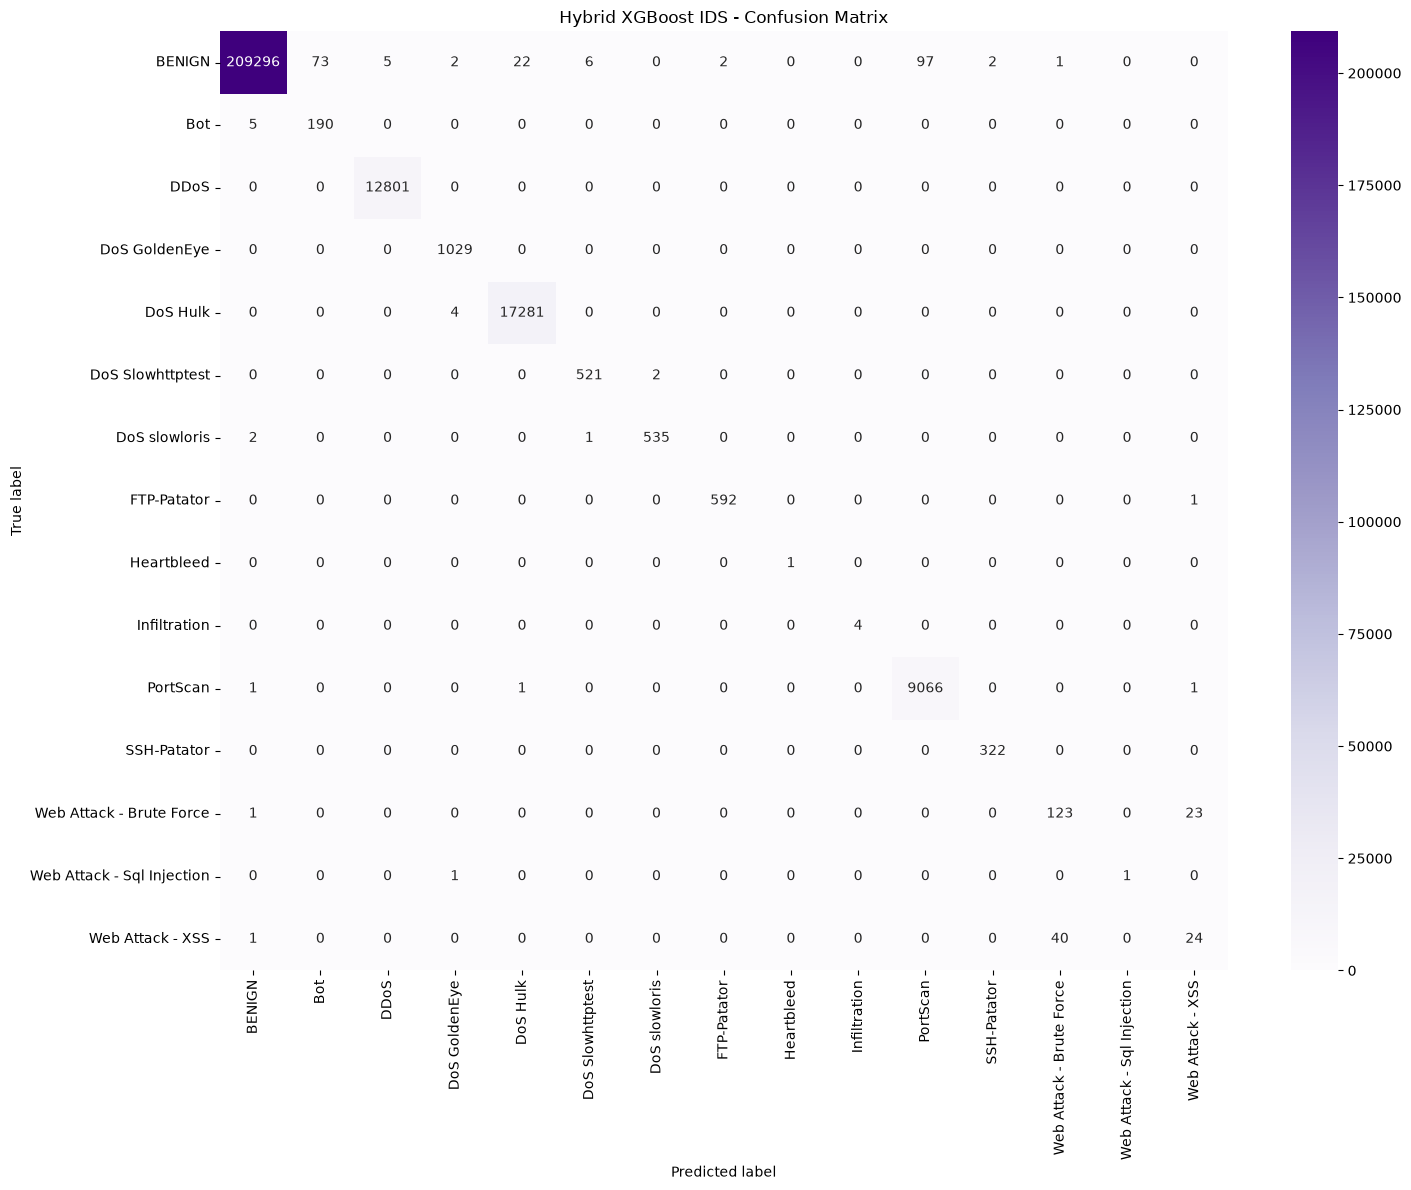


CLASSES RANKED BY RECALL (LOWEST FIRST)


,precision,recall,f1-score,support
Web Attack - XSS,0.4898,0.3692,0.4211,65.0
Web Attack - Sql Injection,1.0000,0.5000,0.6667,2.0
Web Attack - Brute Force,0.7500,0.8367,0.7910,147.0
Bot,0.7224,0.9744,0.8297,195.0
DoS slowloris,0.9963,0.9944,0.9953,538.0
DoS Slowhttptest,0.9867,0.9962,0.9914,523.0
FTP-Patator,0.9966,0.9983,0.9975,593.0
BENIGN,1.0000,0.9990,0.9995,209506.0
PortScan,0.9894,0.9997,0.9945,9069.0
DoS Hulk,0.9987,0.9998,0.9992,17285.0


In [94]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Recover the saved class mapping.
label_mapping = {
    int(class_id): str(label)
    for class_id, label in xgb_bundle["label_mapping"].items()
}

class_ids = sorted(label_mapping.keys())
class_names = [label_mapping[i] for i in class_ids]

# Detailed per-class evaluation.
report = classification_report(
    y_eval,
    hybrid_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).transpose()

print("HYBRID IDS PER-CLASS CLASSIFICATION REPORT")
show_table(report_df.round(4))

# Confusion matrix.
cm = confusion_matrix(y_eval, hybrid_pred, labels=class_ids)

plt.figure(figsize=(15, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.title("Hybrid XGBoost IDS - Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Identify classes with the lowest recall.
class_recall = report_df.loc[
    class_names, ["precision", "recall", "f1-score", "support"]
].sort_values("recall")

print("\nCLASSES RANKED BY RECALL (LOWEST FIRST)")
show_table(class_recall.round(4))
